# 02 · Preprocesamiento y Feature Engineering — Plaza Vea (Abarrotes)

**Curso:** DS3021 Análisis Computacional de Datos · **Proyecto Final – Parte II**

**Objetivo del notebook.** Transformar el dataset oficial extraído en la Parte I (`data/raw/productos_plazavea_raw.csv`, 1438 registros × 12 variables) en dos datasets confiables y documentados:

- `data/processed/productos_plazavea_clean.csv`: los 1438 registros con columnas limpias, variables derivadas y *flags* de calidad (trazabilidad completa).
- `data/processed/productos_plazavea_final.csv`: dataset analítico final (solo productos dentro del alcance *Abarrotes*, columnas reducidas a las analíticas).

**Flujo del notebook:** (1) carga y perfil → (2) integración interna → (3) validación de reglas de dominio → (4) valores faltantes → (5) outliers → (6) transformación → (7) feature engineering → (8) reducción → (9) registro de calidad → (10) exportación y validaciones finales.

> **Alcance de interpretación.** Los datos son un *snapshot* de precios y promociones publicados en el listado web de Abarrotes (30 páginas de un total aproximado de 65) en una fecha de extracción. Es una muestra, no un censo; no contiene información de ventas ni de demanda.

## 0. Configuración

Se importan las librerías del curso (pandas, numpy, matplotlib, seaborn) y se define una paleta sobria y consistente para todas las figuras. Las rutas son relativas a la carpeta `notebooks/` para garantizar reproducibilidad.

In [1]:
import json
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

# Rutas relativas (el notebook se ejecuta desde notebooks/)
RAW_PATH = Path("../data/raw/productos_plazavea_raw.csv")
PROC_DIR = Path("../data/processed")
FIG_DIR = Path("../reports/figures")
TAB_DIR = Path("../reports/tables")
REP_DIR = Path("../reports")
for d in [PROC_DIR, FIG_DIR, TAB_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Paleta sobria y consistente para todo el proyecto
AZUL = "#2F5D7C"
ROJO = "#C8553D"
GRIS = "#8C8C8C"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

def nf(x, d=1):
    # Formatea un número con coma decimal (convención del texto en español): nf(7.9, 2) -> "7,90"
    return f"{x:.{d}f}".replace(".", ",")

def ejes_coma(ax, ejes="xy"):
    # Aplica coma decimal a las etiquetas numéricas de los ejes indicados
    fmt = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))
    for e in ejes:
        getattr(ax, f"{e}axis").set_major_formatter(fmt)

# Metadatos de las figuras de este notebook (el notebook 03 les asigna el número final del informe)
FIGURAS_02 = {}

def guardar_fig(fig, nombre, titulo, pregunta, hallazgo, n=None):
    # Guarda la figura en reports/figures en PNG a 200 dpi y registra sus metadatos
    fig.savefig(FIG_DIR / nombre, dpi=200, bbox_inches="tight", facecolor="white")
    FIGURAS_02[nombre] = {"titulo": titulo, "notebook": "02_preprocessing.ipynb", "pregunta": pregunta,
                          "hallazgo_cifra": hallazgo, "n": n}
    print(f"Figura guardada: reports/figures/{nombre}")

def md_table(df):
    # Convierte un DataFrame en tabla Markdown (sin dependencias externas)
    cols = list(df.columns)
    lineas = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, fila in df.iterrows():
        lineas.append("| " + " | ".join(str(fila[c]).replace("|", "/") for c in cols) + " |")
    return "\n".join(lineas)

# Diccionario donde se acumulan las cifras del preprocesamiento (se exporta al final)
M = {}

## 1. Carga y perfil inicial del dataset

Se carga el CSV oficial **sin modificarlo**. La variable `sku` se lee como texto porque es un identificador (sus longitudes varían entre 2 y 8 caracteres y no tiene sentido operar aritméticamente con ella).

In [2]:
raw = pd.read_csv(RAW_PATH, dtype={"sku": str}, encoding="utf-8")
print("Dimensiones (filas, columnas):", raw.shape)
raw.head()

Dimensiones (filas, columnas): (1438, 12)


,sku,brand,name,category,seller,stock,presentation,current_price,regular_price,discount,product_url,image_url
0,10652532,FIELD,Galletas Saladas FIELD Soda Paquete 6un,Abarrotes / Galletas y Golosinas / Galletas Sa...,plaza vea,True,Bolsa 6un,3.5,3.9,0.0,https://www.plazavea.com.pe/galletas-soda-fiel...,https://plazavea.vteximg.com.br/arquivos/ids/3...
1,1546,SAN JORGE,Galletas de Soda SAN JORGE Paquete 7un,Abarrotes / Galletas y Golosinas / Galletas Sa...,plaza vea,True,Paquete 7un,3.8,4.5,0.0,https://www.plazavea.com.pe/galletas-de-soda-s...,https://plazavea.vteximg.com.br/arquivos/ids/2...
2,10322535,FIELD,Galletas FIELD Charada Paquete 6un,Abarrotes / Galletas y Golosinas / Galletas Du...,plaza vea,True,Paquete 226.8g,5.3,5.3,0.0,https://www.plazavea.com.pe/galletas-field-cha...,https://plazavea.vteximg.com.br/arquivos/ids/2...
3,10918189,FIELD,Galletas Saladas FIELD Cream Cracker Paquete 7...,Abarrotes / Galletas y Golosinas / Galletas Sa...,plaza vea,True,"Paquete 73,5g",2.1,2.5,0.0,https://www.plazavea.com.pe/galletas-field-cre...,NaN
4,1834,MOROCHAS,Galletas MOROCHAS Paquete 180g,Abarrotes / Galletas y Golosinas / Galletas Du...,plaza vea,True,Paquete 180g,4.7,5.9,0.0,https://www.plazavea.com.pe/galletas-morochas-...,NaN


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1438 entries, 0 to 1437
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   sku            1438 non-null   str    
 1   brand          1438 non-null   str    
 2   name           1438 non-null   str    
 3   category       1438 non-null   str    
 4   seller         1438 non-null   str    
 5   stock          1438 non-null   bool   
 6   presentation   1300 non-null   str    
 7   current_price  1438 non-null   float64
 8   regular_price  1438 non-null   float64
 9   discount       1438 non-null   float64
 10  product_url    1438 non-null   str    
 11  image_url      79 non-null     str    
dtypes: bool(1), float64(3), str(8)
memory usage: 125.1 KB


In [4]:
# Tipos de dato, cardinalidad y valores faltantes por variable
perfil = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unicos": raw.nunique(),
    "n_nulos": raw.isna().sum(),
    "pct_nulos": (raw.isna().mean() * 100).round(2),
})
perfil

,dtype,n_unicos,n_nulos,pct_nulos
sku,str,1438,0,0.00
brand,str,275,0,0.00
name,str,1438,0,0.00
category,str,71,0,0.00
seller,str,1,0,0.00
stock,bool,1,0,0.00
presentation,str,464,138,9.60
current_price,float64,275,0,0.00
regular_price,float64,285,0,0.00
discount,float64,1,0,0.00


In [5]:
# Estadísticos descriptivos de las variables numéricas
raw.describe().round(2)

,current_price,regular_price,discount
count,1438.00,1438.00,1438.0
mean,10.70,11.33,0.0
std,9.49,10.03,0.0
min,0.80,0.80,0.0
25%,4.90,5.12,0.0
50%,7.90,8.50,0.0
75%,13.88,14.50,0.0
max,89.20,105.00,0.0


In [6]:
# Estadísticos de las variables de texto/booleanas
raw.describe(include=["object", "string", "bool"])

,sku,brand,name,category,seller,stock,presentation,product_url,image_url
count,1438,1438,1438,1438,1438,1438,1300,1438,79
unique,1438,275,1438,71,1,1,464,1438,79
top,10652532,BELL'S,Galletas Saladas FIELD Soda Paquete 6un,Abarrotes / Galletas y Golosinas / Galletas Du...,plaza vea,True,Bolsa 500g,https://www.plazavea.com.pe/galletas-soda-fiel...,https://plazavea.vteximg.com.br/arquivos/ids/3...
freq,1,184,1,106,1438,1438,72,1,1


In [7]:
M["raw_filas"] = int(raw.shape[0])
M["raw_columnas"] = int(raw.shape[1])
M["raw_sku_unicos"] = int(raw["sku"].nunique())
M["nulos_presentation"] = int(raw["presentation"].isna().sum())
M["pct_nulos_presentation"] = round(raw["presentation"].isna().mean() * 100, 2)
M["nulos_image_url"] = int(raw["image_url"].isna().sum())
M["pct_nulos_image_url"] = round(raw["image_url"].isna().mean() * 100, 2)
print(json.dumps(M, indent=2, ensure_ascii=False))

{
  "raw_filas": 1438,
  "raw_columnas": 12,
  "raw_sku_unicos": 1438,
  "nulos_presentation": 138,
  "pct_nulos_presentation": 9.6,
  "nulos_image_url": 1359,
  "pct_nulos_image_url": 94.51
}


**Conclusión del perfil.** El dataset tiene **1438 registros × 12 variables** y 1438 SKU únicos, en concordancia con la cifra oficial de la Parte I. Solo dos variables presentan nulos: `presentation` (138; 9,6 %) e `image_url` (1359; 94,5 %). Esto **corrige** lo reportado en la Parte I (≈0,07 % de nulos solo en `presentation`). Además, `seller` y `stock` tienen un único valor, y `discount` tiene mínimo y máximo iguales a 0, lo que se analiza en la sección 3.

## 2. Integración interna de datos

El proyecto tiene **una sola fuente de datos** (el listado web de Abarrotes de Plaza Vea). La integración realizada fue **interna**: el notebook de adquisición recorrió las páginas `https://www.plazavea.com.pe/abarrotes?page=N` para N = 1…30 y **concatenó** los productos de cada página en una única tabla. No se incorpora ninguna fuente externa.

Para que esa consolidación sea válida se controlan dos aspectos:

1. **Reconciliación de estructura:** todas las páginas se extrajeron con el mismo parser, por lo que la tabla consolidada debe tener exactamente las 12 columnas esperadas, con tipos coherentes.
2. **Control de duplicados por SKU:** un mismo producto puede aparecer en dos páginas si el listado se reordena durante la extracción; por eso la clave de integración es `sku`.

In [8]:
COLUMNAS_ESPERADAS = ["sku", "brand", "name", "category", "seller", "stock", "presentation",
                      "current_price", "regular_price", "discount", "product_url", "image_url"]
print("¿Estructura idéntica a la esperada (12 columnas, mismo orden)?",
      list(raw.columns) == COLUMNAS_ESPERADAS)

# Control de integración por SKU
n_antes = len(raw)
n_dup = int(raw.duplicated(subset="sku").sum())
integrado = raw.drop_duplicates(subset="sku", keep="first").copy()
n_despues = len(integrado)
control_integracion = pd.DataFrame({
    "registros_antes": [n_antes], "duplicados_sku": [n_dup],
    "eliminados": [n_antes - n_despues], "registros_despues": [n_despues],
})
# Controles adicionales: duplicados exactos de fila, de URL y de nombre
print("Duplicados de fila completa:", int(raw.duplicated().sum()))
print("Duplicados de product_url:", int(raw["product_url"].duplicated().sum()))
print("Duplicados de name:", int(raw["name"].duplicated().sum()))
control_integracion

¿Estructura idéntica a la esperada (12 columnas, mismo orden)? True
Duplicados de fila completa: 0
Duplicados de product_url: 0
Duplicados de name: 0


,registros_antes,duplicados_sku,eliminados,registros_despues
0,1438,0,0,1438


In [9]:
M["integracion"] = control_integracion.iloc[0].astype(int).to_dict()
df = integrado.reset_index(drop=True)

**Conclusión.** La tabla consolidada conserva la estructura esperada (12 columnas) y el control por SKU arroja **1438 registros antes / 0 duplicados / 0 eliminados / 1438 después**. Tampoco hay duplicados de URL ni de nombre. Esto es coherente con el notebook de adquisición, que ya aplicaba `drop_duplicates(subset="sku")`. Las cifras 1407/1397 que aparecen en las salidas del notebook adjunto corresponden a otra corrida y se mencionan solo como nota de trazabilidad.

## 3. Validación de reglas de dominio

Se definen reglas que todo registro de un catálogo de precios debe cumplir y se cuenta cuántos registros las incumplen. Las reglas cubren precios, descuento, URLs, variables constantes, cadenas de texto y categorías.

### 3.1 Reglas de precio y descuento

In [10]:
# Descuento "calculable" a partir de los dos precios (en %)
dif_precio = df["regular_price"] - df["current_price"]
discount_calc = (dif_precio / df["regular_price"] * 100).round(2)
TOL = 0.005  # tolerancia en S/ para considerar que hay rebaja real (evita ruido de redondeo)
con_rebaja = dif_precio > TOL

reglas = pd.DataFrame([
    ("current_price > 0", int((df["current_price"] <= 0).sum())),
    ("regular_price > 0", int((df["regular_price"] <= 0).sum())),
    ("current_price <= regular_price", int((df["current_price"] > df["regular_price"]).sum())),
    ("0 <= discount <= 100 (almacenado)", int((~df["discount"].between(0, 100)).sum())),
    ("discount almacenado = 0 pero current_price < regular_price", int(((df["discount"] == 0) & con_rebaja).sum())),
    ("discount almacenado coherente con el calculable (|dif| <= 1 p.p.)",
     int(((df["discount"] - discount_calc).abs() > 1).sum())),
], columns=["regla", "n_incumple"])
reglas["pct_incumple"] = (reglas["n_incumple"] / len(df) * 100).round(2)
reglas

,regla,n_incumple,pct_incumple
0,current_price > 0,0,0.00
1,regular_price > 0,0,0.00
2,current_price <= regular_price,0,0.00
3,0 <= discount <= 100 (almacenado),0,0.00
4,discount almacenado = 0 pero current_price < r...,479,33.31
5,discount almacenado coherente con el calculabl...,478,33.24


In [11]:
print("Rango current_price: S/", df["current_price"].min(), "–", df["current_price"].max())
print("Rango regular_price: S/", df["regular_price"].min(), "–", df["regular_price"].max())
print("discount almacenado: min =", df["discount"].min(), "| max =", df["discount"].max(),
      "| % de ceros =", round((df["discount"] == 0).mean() * 100, 1))
print("Productos con current_price < regular_price:", int(con_rebaja.sum()),
      f"({con_rebaja.mean()*100:.1f} %)")
print("Rango del descuento calculable: ", discount_calc.min(), "% –", discount_calc.max(), "%")

M["precio_actual_min"] = float(df["current_price"].min()); M["precio_actual_max"] = float(df["current_price"].max())
M["precio_regular_min"] = float(df["regular_price"].min()); M["precio_regular_max"] = float(df["regular_price"].max())
M["discount_almacenado_pct_ceros"] = round((df["discount"] == 0).mean() * 100, 2)
M["n_con_rebaja_raw"] = int(con_rebaja.sum())
M["discount_calc_max"] = float(discount_calc.max())

Rango current_price: S/ 0.8 – 89.2
Rango regular_price: S/ 0.8 – 105.0
discount almacenado: min = 0.0 | max = 0.0 | % de ceros = 100.0
Productos con current_price < regular_price: 479 (33.3 %)
Rango del descuento calculable:  0.0 % – 38.14 %


**Hallazgo crítico.** Las reglas de precio se cumplen: no hay precios ≤ 0 ni casos con `current_price > regular_price`. Sin embargo, `discount` vale **0 en el 100 % de los registros**, mientras que **479 productos (33,3 %)** muestran `current_price < regular_price`. Es decir, el descuento almacenado **no es coherente** con los precios. (La regla de coherencia con tolerancia de 1 p.p. marca 478 y no 479 casos porque un producto tiene un descuento calculable de solo 0,69 %.) Revisando el notebook de adquisición, el descuento se extraía con la expresión regular `(-\d+)%` sobre un texto de la tarjeta y luego se aplicaba `fillna(0)`; si el selector no encontró el texto “-X%” en la corrida oficial, todos los valores quedaron en 0. **Decisión:** `discount` se considera inválido y se reconstruye como `discount_pct = (regular_price − current_price) / regular_price × 100` (rango observado ≈ 0–38,1 %).

### 3.2 URLs, stock y vendedor

In [12]:
dominio_url = df["product_url"].str.extract(r"https?://([^/]+)")[0]
dominio_img = df["image_url"].dropna().str.extract(r"https?://([^/]+)")[0]
print("Dominios de product_url:\n", dominio_url.value_counts(dropna=False).to_string())
print("product_url nulos:", int(df["product_url"].isna().sum()),
      "| terminan en '/p':", int(df["product_url"].str.endswith("/p").sum()))
print("\nDominios de image_url (no nulos):\n", dominio_img.value_counts().to_string())
print("\nValores de stock:\n", df["stock"].value_counts(dropna=False).to_string())
print("\nValores de seller:\n", df["seller"].value_counts(dropna=False).to_string())

Dominios de product_url:
 0
www.plazavea.com.pe    1438
product_url nulos: 0 | terminan en '/p': 1438

Dominios de image_url (no nulos):
 0
plazavea.vteximg.com.br    79

Valores de stock:
 stock
True    1438

Valores de seller:
 seller
plaza vea    1438


**Conclusión.** El 100 % de `product_url` pertenece a `www.plazavea.com.pe`, sin nulos ni duplicados; las `image_url` disponibles provienen del CDN `plazavea.vteximg.com.br`. `stock` es `True` y `seller` es “plaza vea” en el **100 %** de los registros: son variables de **varianza cero**. Es plausible que el listado web muestre solo productos disponibles vendidos por la propia tienda, por lo que estas variables no permiten segmentar y se excluirán del dataset analítico (sección 8).

### 3.3 Cadenas de texto y variantes de marca

Se revisan espacios sobrantes y uso de mayúsculas. Para detectar variantes de una misma marca de forma **sistemática** (no manual), se construye una clave normalizada: minúsculas y solo caracteres alfanuméricos. Luego se repite con una clave que además elimina acentos, para capturar marcas que difieren solo por tildes o apóstrofes.

In [13]:
cols_texto = ["sku", "brand", "name", "category", "seller", "presentation", "product_url"]
espacios = pd.DataFrame({
    "espacios_extremos": [int((df[c].dropna() != df[c].dropna().str.strip()).sum()) for c in cols_texto],
    "dobles_espacios": [int(df[c].dropna().str.contains(r"\s{2,}").sum()) for c in cols_texto],
}, index=cols_texto)
print("Marcas que no están completamente en mayúsculas:", int((df["brand"] != df["brand"].str.upper()).sum()))
espacios

Marcas que no están completamente en mayúsculas: 0


,espacios_extremos,dobles_espacios
sku,0,0
brand,0,0
name,0,5
category,0,0
seller,0,0
presentation,0,8
product_url,0,0


In [14]:
def quitar_acentos(s):
    # Elimina tildes/diacríticos (É -> E, Ñ -> N)
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

clave_alnum = df["brand"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
clave_sin_acentos = df["brand"].map(quitar_acentos).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)

def variantes(clave):
    # Agrupa las marcas por clave y devuelve las claves con más de una escritura
    g = df.groupby(clave)["brand"].agg(lambda s: dict(s.value_counts()))
    return g[g.map(len) > 1]

print("(a) Variantes por clave alfanumérica en minúsculas:")
print(variantes(clave_alnum).to_string())
print("\n(b) Variantes adicionales al eliminar acentos:")
print(variantes(clave_sin_acentos).to_string())

# (c) Apóstrofo perdido: marcas que terminan en " S" (p. ej. "LIBBY S"). La escritura correcta se
#     reconstruye a partir del propio nombre del producto: "X'S" si aparece en name; si no, "XS".
def reconstruir_s(marca):
    base = marca[:-2]
    nombres = df.loc[df["brand"] == marca, "name"].str.upper()
    if nombres.str.contains(base + "'S", regex=False).any():
        return base + "'S"
    if nombres.str.contains(base + "S", regex=False).any():
        return base + "S"
    return marca

marcas_s = sorted(b for b in df["brand"].unique() if re.search(r"\w S$", b))
MAPA_APOSTROFO = {b: reconstruir_s(b) for b in marcas_s}
tabla_apostrofo = pd.DataFrame([{"marca_publicada": b, "n": int((df["brand"] == b).sum()),
                                 "escritura_en_name": MAPA_APOSTROFO[b],
                                 "ejemplo_name": df.loc[df["brand"] == b, "name"].iloc[0]} for b in marcas_s])
print("\n(c) Marcas con apóstrofo perdido (terminan en ' S'):")
display(tabla_apostrofo)

# (d) Submarcas: marcas cuyo texto empieza con otra marca existente seguida de un espacio
marcas_u = sorted(df["brand"].unique())
submarcas = pd.DataFrame([{"marca": b, "n_marca": int((df["brand"] == b).sum()),
                           "submarca": s, "n_submarca": int((df["brand"] == s).sum())}
                          for b in marcas_u for s in marcas_u if s.startswith(b + " ")])
print("(d) Pares marca / submarca detectados por prefijo:")
display(submarcas)
print("Marcas únicas (raw):", df["brand"].nunique())

(a) Variantes por clave alfanumérica en minúsculas:
brand
casaverde    {'CASA VERDE': 18, 'CASAVERDE': 1}
lays                   {'LAY'S': 16, 'LAYS': 1}

(b) Variantes adicionales al eliminar acentos:


brand
casaverde    {'CASA VERDE': 18, 'CASAVERDE': 1}
lays                   {'LAY'S': 16, 'LAYS': 1}
nestle              {'NESTLÉ': 11, 'NESTLE': 1}



(c) Marcas con apóstrofo perdido (terminan en ' S'):


,marca_publicada,n,escritura_en_name,ejemplo_name
0,CRICKET S,8,CRICKETS,Chifles CRICKETS Sabor a Leche de Tigre Bolsa ...
1,HELLMANN S,5,HELLMANN'S,Mayonesa Clásica HELLMANN'S Doypack 475g
2,LIBBY S,10,LIBBY'S,Mayonesa LIBBY'S Doypack 100g
3,SNYDER S,1,SNYDER'S,Piqueo SNYDER'S PRETZELS Snaps bajo en grasa B...


(d) Pares marca / submarca detectados por prefijo:


,marca,n_marca,submarca,n_submarca
0,BON BON,1,BON BON BUM,1
1,COSTA,41,COSTA NIK,1
2,EL CORTE INGLÉS,9,EL CORTE INGLÉS SELECTION,6
3,MEXI,2,MEXI NACHOS,1
4,NABISCO,2,NABISCO RITZ,1
5,NESTLE,1,NESTLE MOROCHAS,1
6,NESTLE,1,NESTLE SUBLIME,4
7,VICTORIA,13,VICTORIA GLACITAS,6
8,VICTORIA,13,VICTORIA TENTACION,4


Marcas únicas (raw): 275


**Conclusión.** No hay espacios sobrantes en los extremos y todas las marcas están en mayúsculas, pero hay **dobles espacios internos** en 5 nombres (p. ej. “Papas INKA CHIPS Nativas␣␣Bolsa 135g”) y 8 presentaciones (p. ej. “Lata␣␣35g”); se colapsarán a un espacio en la sección 6. La detección sistemática encuentra:

- **(a, b) Tres grupos de variantes de escritura:** `CASA VERDE` (18) / `CASAVERDE` (1), `LAY'S` (16) / `LAYS` (1) y, al quitar acentos, `NESTLÉ` (11) / `NESTLE` (1). **Decisión:** unificar cada grupo en su escritura más frecuente.
- **(c) Cuatro marcas con el apóstrofo convertido en espacio** (error de captura): `CRICKET S` (8), `HELLMANN S` (5), `LIBBY S` (10) y `SNYDER S` (1). **Decisión:** reconstruir la escritura a partir del propio nombre del producto, que es la regla verificable: `HELLMANN'S`, `LIBBY'S` y `SNYDER'S` (el nombre contiene “X'S”) y `CRICKETS` (el nombre escribe “CRICKETS”, sin apóstrofo). Ninguna de ellas tiene otra escritura en el dataset, por lo que los conteos por marca no cambian; solo se corrige el texto.
- **(d) Submarcas:** el prefijo detecta pares como `VICTORIA` / `VICTORIA GLACITAS` / `VICTORIA TENTACION`, `COSTA` / `COSTA NIK` o `NABISCO` / `NABISCO RITZ`; también conviven `FRITO LAY` y `LAY'S`. **Decisión:** se conservan como marcas distintas porque así las publica el retailer y no hay una regla objetiva para decidir el nivel de agregación (además, el prefijo genera falsos positivos, como `BON BON` / `BON BON BUM`). Efecto: en el ranking de marcas con n ≥ 10 del notebook 03, `VICTORIA` aparece con sus 13 productos propios, sin sumar los de sus submarcas.

En todos los casos la marca original se conserva en `brand_original` para trazabilidad.

### 3.4 Categorías

In [15]:
niveles = df["category"].str.split(" / ")
print("Número de niveles por categoría:\n", niveles.str.len().value_counts().sort_index().to_string())
print("\nNivel 1:\n", niveles.str[0].value_counts().to_string())
print("\nCategorías con solo 2 niveles:\n", df.loc[niveles.str.len() == 2, "category"].value_counts().to_string())
print("\nRegistros fuera del alcance Abarrotes/Packs:")
df.loc[~niveles.str[0].isin(["Abarrotes", "Packs"]), ["sku", "name", "category"]]

Número de niveles por categoría:
 category
2      62
3    1376

Nivel 1:
 category
Abarrotes            1377
Packs                  60
Frutas y Verduras       1

Categorías con solo 2 niveles:
 category
Packs / Packs Abarrotes                     60
Abarrotes / Salsas, Cremas y Condimentos     2

Registros fuera del alcance Abarrotes/Packs:


,sku,name,category
626,9431,Fideo Chino SAN SEN Bolsa 500g,Frutas y Verduras / Verduras / Verduras Orient...


**Conclusión.** `category` tiene 71 valores con estructura jerárquica “Nivel 1 / Nivel 2 / Nivel 3”. El nivel 1 es *Abarrotes* (1377), *Packs* (60) o *Frutas y Verduras* (1). Hay 62 registros con solo dos niveles (los 60 packs y 2 de “Salsas, Cremas y Condimentos”). **Decisión:** separar la jerarquía en `category_level1`, `category_group` (nivel 2) y `subcategory` (nivel 3; si no existe, se repite el nivel 2). El único producto de *Frutas y Verduras* (“Verduras Orientales”) está fuera del alcance del proyecto y se marca con `in_scope = False`. Cabe notar que el producto es un fideo chino (“Fideo Chino SAN SEN Bolsa 500g”) que el propio retailer cataloga en *Frutas y Verduras*; se respeta la clasificación del catálogo porque es la regla reproducible y verificable que define el alcance, y el impacto es de un solo registro.

## 4. Tratamiento de valores faltantes

Para cada variable con nulos se analiza su relevancia analítica, el mecanismo plausible que genera el faltante y el tratamiento adoptado.

In [16]:
faltantes = pd.DataFrame({
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["n_nulos"] > 0]
faltantes["relevancia"] = ["Media: describe el envase/tamaño", "Baja: solo trazabilidad visual"]
faltantes["mecanismo_plausible"] = [
    "No aleatorio (ver 4.1): el faltante se asocia a productos con rebaja y a Packs; la información sí está en el nombre",
    "Técnico: lazy-loading de imágenes; Selenium no hizo scroll hasta cada tarjeta (hipótesis)",
]
faltantes["tratamiento"] = ["Imputación por regex desde name + flag presentation_imputed",
                            "Sin imputación; se excluye del dataset analítico"]
faltantes

,n_nulos,pct_nulos,relevancia,mecanismo_plausible,tratamiento
presentation,138,9.60,Media: describe el envase/tamaño,No aleatorio (ver 4.1): el faltante se asocia ...,Imputación por regex desde name + flag present...
image_url,1359,94.51,Baja: solo trazabilidad visual,Técnico: lazy-loading de imágenes; Selenium no...,Sin imputación; se excluye del dataset analítico


Figura guardada: reports/figures/fig01_valores_faltantes.png


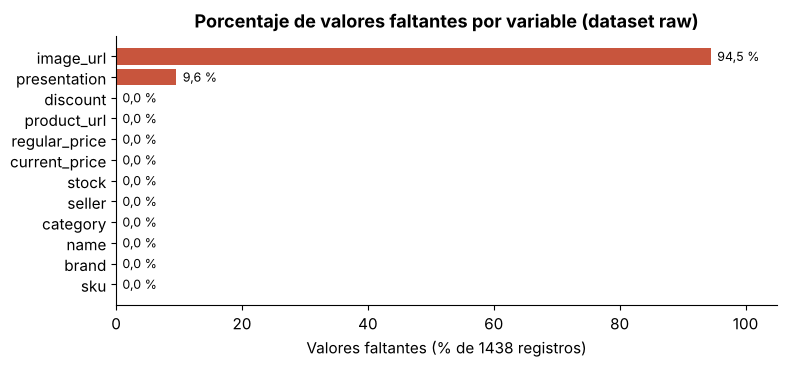

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
pct = (df.isna().mean() * 100).sort_values()
colores = [ROJO if v > 0 else GRIS for v in pct]
ax.barh(pct.index, pct.values, color=colores)
for i, v in enumerate(pct.values):
    ax.text(v + 1, i, f"{nf(v)} %", va="center", fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel(f"Valores faltantes (% de {len(df)} registros)")
ejes_coma(ax, "x")
ax.set_title("Porcentaje de valores faltantes por variable (dataset raw)")
plt.tight_layout()
guardar_fig(fig, "fig01_valores_faltantes.png", "Porcentaje de valores faltantes por variable (dataset raw)",
            "Preprocesamiento: ¿qué variables tienen faltantes y en qué proporción?",
            f"image_url {nf(M['pct_nulos_image_url'])} % y presentation {nf(M['pct_nulos_presentation'])} % de nulos; "
            "las demás variables, 0 %", n=len(df))
plt.show()

**Conclusión.** Solo dos variables tienen faltantes y su naturaleza es distinta: `presentation` (9,6 %) es recuperable porque el nombre del producto termina con el envase y la cantidad; `image_url` (94,5 %) responde a un problema técnico de carga diferida y no aporta al análisis de precios.

### 4.1 Imputación de `presentation` desde `name`

Los nombres siguen el patrón “… **Envase cantidad+unidad**” al final (p. ej. *“Arroz Extra BELL'S Bolsa 5Kg”*). Se construye una expresión regular con los **25 tipos de envase observados** en los valores no nulos de `presentation` y unidades de medida (g, kg, ml, L, un, etc.), admitiendo un multiplicador final (“x 2”). La unidad se estandariza (Kg, g, ml, L, un). No se eliminan filas.

In [18]:
# Tipos de envase observados en las presentaciones no nulas
envases = sorted(df["presentation"].dropna().str.split(" ").str[0].unique())
print("Envases observados:", envases)

patron = re.compile(
    r"(?P<envase>" + "|".join(envases) + r")\s+"
    r"(?P<cant>\d+(?:[.,]\d+)?)\s*(?P<unidad>kg|gr|g|ml|l|un|cc|oz)\b"
    r"(?P<mult>\s*x\s*\d+(?:[.,]\d+)?\s*(?:kg|gr|g|ml|l|un)?)?\s*$",
    flags=re.IGNORECASE,
)
UNIDADES = {"kg": "Kg", "gr": "g", "g": "g", "ml": "ml", "l": "L", "un": "un", "cc": "ml", "oz": "oz"}

def presentacion_desde_nombre(nombre):
    # Devuelve "Envase cantidad+unidad" (y multiplicador) si el nombre lo contiene al final
    m = patron.search(nombre)
    if m is None:
        return np.nan
    envase = m.group("envase").capitalize()
    texto = f"{envase} {m.group('cant')}{UNIDADES[m.group('unidad').lower()]}"
    if m.group("mult"):
        texto += " " + re.sub(r"\s+", " ", m.group("mult").strip())
    return texto

# Validación del método en los registros que sí tienen presentation: ¿coincide el tipo de envase?
no_nulos = df[df["presentation"].notna()]
pred = no_nulos["name"].map(presentacion_desde_nombre)
cobertura = pred.notna().mean() * 100
coincide_envase = (pred.dropna().str.split(" ").str[0].str.lower()
                   == no_nulos.loc[pred.notna(), "presentation"].str.split(" ").str[0].str.lower()).mean() * 100
print(f"Validación en no nulos: el patrón se encuentra en {cobertura:.1f} % de los nombres; "
      f"el envase coincide con el publicado en {coincide_envase:.1f} % de esos casos.")

Envases observados: ['Balde', 'Bandeja', 'Barra', 'Bidón', 'Bolsa', 'Botella', 'Caja', 'Display', 'Doypack', 'Empaque', 'Envase', 'Envoltura', 'Frasco', 'Galonera', 'Lata', 'Pack', 'Paquete', 'Pote', 'Saco', 'Sobre', 'Spray', 'Tableta', 'Tetrapack', 'Táper', 'Vaso']
Validación en no nulos: el patrón se encuentra en 98.2 % de los nombres; el envase coincide con el publicado en 91.0 % de esos casos.


In [19]:
nulos_pres = df["presentation"].isna()
imputada = df.loc[nulos_pres, "name"].map(presentacion_desde_nombre)
df["presentation_imputed"] = nulos_pres.astype(int)
df.loc[nulos_pres, "presentation"] = imputada.fillna("No especificado")

n_recuperados = int(imputada.notna().sum())
n_no_esp = int(imputada.isna().sum())
print(f"Nulos originales: {int(nulos_pres.sum())} | recuperados por regex: {n_recuperados} "
      f"({n_recuperados/nulos_pres.sum()*100:.1f} %) | quedan 'No especificado': {n_no_esp}")
M["presentation_recuperados"] = n_recuperados
M["presentation_no_especificado"] = n_no_esp
M["presentation_validacion_cobertura_pct"] = round(cobertura, 2)
M["presentation_validacion_envase_coincide_pct"] = round(coincide_envase, 2)

print("\nEjemplos de imputación:")
display(df.loc[nulos_pres, ["name", "presentation"]].head(8))
no_rec = df.loc[nulos_pres & (df["presentation"] == "No especificado"), ["name", "presentation"]]
print("Casos no recuperables:", len(no_rec))
if len(no_rec) > 0:
    display(no_rec)
print("\nCasos de formato atípico resueltos gracias a IGNORECASE y al multiplicador opcional:")
display(df.loc[nulos_pres & df["name"].str.contains(r"paquete 6 un|205Gr|10 un x", regex=True), ["name", "presentation"]])

Nulos originales: 138 | recuperados por regex: 138 (100.0 %) | quedan 'No especificado': 0

Ejemplos de imputación:


,name,presentation
11,Galletas Saladitas BELL'S Paquete 6un,Paquete 6un
14,Arroz Extra BELL'S Bolsa 5Kg,Bolsa 5Kg
27,Tortilla Chips DORITOS Queso Atrevido Bolsa 45g,Bolsa 45g
35,Caramelos TIC TAC Menta Intensa Envase 16g,Envase 16g
70,Pack Galletas OREO Sabor a Fresa Paquete 6un x 2,Paquete 6un x 2
77,Filete de Atún en Agua BELL'S Lata 140g,Lata 140g
79,Fideos DON VITTORIO Spaghetti Bolsa 950g,Bolsa 950g
82,Azúcar Rubia BELL'S Bolsa 5Kg,Bolsa 5Kg


Casos no recuperables: 0

Casos de formato atípico resueltos gracias a IGNORECASE y al multiplicador opcional:


,name,presentation
350,Pack Galletas MOROCHAS paquete 6 un x 2,Paquete 6un x 2
635,Aderezo BELL'S Con ají panca molido y especias...,Frasco 205g
1204,Goma de Mascar TRIDENT X Splash Sabor a Yerbab...,Caja 10un x 17.1g


**¿El faltante de `presentation` es aleatorio?** Antes de imputar conviene saber si los registros sin presentación se parecen al resto. Se comparan los 138 registros con `presentation_imputed = 1` frente a los 1300 restantes en la presencia de rebaja (`current_price < regular_price`) y en su grupo de categoría.

In [20]:
rebaja_raw = con_rebaja.astype(int).rename("has_discount")
grupo_raw = df["category"].str.split(" / ").str[1]
es_packs_cat = df["category"].str.startswith("Packs")

def tasa_por_imputacion(mascara):
    # n, productos con rebaja y tasa (%) según presentation_imputed, dentro de la máscara indicada
    t = (pd.DataFrame({"presentation_imputed": df["presentation_imputed"], "has_discount": rebaja_raw})[mascara]
           .groupby("presentation_imputed")["has_discount"].agg(n="size", n_promo="sum", promo_rate_pct="mean"))
    t["promo_rate_pct"] = (t["promo_rate_pct"] * 100).round(1)
    return t

mec_total = tasa_por_imputacion(pd.Series(True, index=df.index))
mec_sin_packs = tasa_por_imputacion(~es_packs_cat)
print("Presencia de rebaja según presentation_imputed (1438 registros):"); display(mec_total)
print("Lo mismo excluyendo la categoría Packs:"); display(mec_sin_packs)

imp_grupo = pd.crosstab(grupo_raw, df["presentation_imputed"]).rename(columns={0: "n_no_imputado", 1: "n_imputado"})
imp_grupo["n"] = imp_grupo["n_no_imputado"] + imp_grupo["n_imputado"]
imp_grupo["pct_imputado"] = (imp_grupo["n_imputado"] / imp_grupo["n"] * 100).round(1)
imp_grupo = imp_grupo.sort_values("n_imputado", ascending=False)
print("Distribución de los imputados por grupo de categoría:"); display(imp_grupo)

M["presentation_mecanismo"] = {
    "promo_rate_por_imputacion": {str(k): {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": float(r.promo_rate_pct)}
                                  for k, r in mec_total.iterrows()},
    "promo_rate_por_imputacion_sin_packs": {str(k): {"n": int(r.n), "n_promo": int(r.n_promo), "promo_rate_pct": float(r.promo_rate_pct)}
                                            for k, r in mec_sin_packs.iterrows()},
    "n_imputados_en_packs": int(imp_grupo.loc["Packs Abarrotes", "n_imputado"]),
    "pct_imputado_en_packs": float(imp_grupo.loc["Packs Abarrotes", "pct_imputado"]),
    "pct_imputado_global": round(df["presentation_imputed"].mean() * 100, 2),
    "imputados_por_grupo": {g: int(v) for g, v in imp_grupo["n_imputado"].items() if v > 0},
}

Presencia de rebaja según presentation_imputed (1438 registros):


,n,n_promo,promo_rate_pct
presentation_imputed,,,
0,1300,403,31.0
1,138,76,55.1


Lo mismo excluyendo la categoría Packs:


,n,n_promo,promo_rate_pct
presentation_imputed,,,
0,1277,380,29.8
1,101,39,38.6


Distribución de los imputados por grupo de categoría:


presentation_imputed,n_no_imputado,n_imputado,n,pct_imputado
category,,,,
Packs Abarrotes,23,37,60,61.7
"Fideos, Pastas y Salsas",109,31,140,22.1
Snacks y Piqueos,210,18,228,7.9
"Salsas, Cremas y Condimentos",290,15,305,4.9
Chocolatería,104,11,115,9.6
Galletas y Golosinas,243,11,254,4.3
Conservas,113,7,120,5.8
Azúcar y Endulzantes,37,5,42,11.9
Arroz,33,1,34,2.9


**Conclusión: el faltante no es aleatorio (no MCAR).** Entre los 138 registros sin presentación, el 55,1 % tiene rebaja, frente al 31,0 % de los 1300 con presentación publicada. Parte de la diferencia se debe a *Packs Abarrotes*: 37 de los 138 imputados son packs (el 61,7 % de esa categoría, frente al 9,6 % global), y todos los packs tienen rebaja. Aun excluyendo la categoría Packs, la diferencia se mantiene (38,6 % frente a 29,8 %). Una explicación plausible, no verificable sin el HTML original, es que las tarjetas con promoción o de packs omiten el bloque de presentación. **Implicaciones:** (1) eliminar estas filas habría sesgado a la baja la tasa promocional, lo que refuerza la decisión de imputar y no eliminar; (2) `presentation_imputed` no es solo trazabilidad: en el notebook 03 se usa para medir la sensibilidad de la tasa promocional a los registros imputados.

**Conclusión e impacto.** De los **138** nulos de `presentation`, la regex recupera **los 138 (100 %)** y **ninguno** queda como “No especificado” (la categoría se mantiene en el código como respaldo para futuras corridas). Los formatos atípicos (“paquete 6 un x 2”, “Frasco 205Gr”, “Caja 10 un x 17.1g”) se resuelven porque el patrón ignora mayúsculas, admite espacio entre cantidad y unidad y un multiplicador final. **Validación del método:** en los 1300 registros con presentación publicada, el patrón aparece en el 98,2 % de los nombres y el tipo de envase coincide con el publicado en el 91,0 % de esos casos; las discrepancias se deben a que la web a veces describe el mismo producto con envases distintos en el nombre y en la tarjeta (p. ej. “Paquete” vs. “Bolsa”). Por eso se crea `presentation_imputed` (1 = valor derivado del nombre), que permite aislar estos registros. Como se muestra a continuación, el faltante no es aleatorio; aun así, la imputación no elimina filas y su efecto sobre la tasa promocional se cuantifica en el notebook 03.

### 4.2 `image_url`

No se imputa: una URL de imagen no puede deducirse con certeza y la variable no participa en el análisis de precios y promociones. Se conserva en el dataset limpio completo (trazabilidad) y se excluye del dataset analítico.

## 5. Detección y tratamiento de outliers

Se aplica el criterio del **rango intercuartílico (IQR)**: un valor es atípico si está fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. Se analizan `current_price`, `regular_price` y el descuento reconstruido `discount_pct`. Para `discount_pct` el IQR se calcula **solo entre productos con rebaja**, porque el 66,7 % de ceros es estructural (productos sin promoción) y distorsionaría los cuartiles.

In [21]:
df["discount_pct"] = discount_calc.where(con_rebaja, 0.0)

def limites_iqr(serie):
    # Q1, Q3, IQR y límites del criterio 1,5·IQR SIN redondear (el redondeo es solo para mostrar)
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "lim_inf": q1 - 1.5 * iqr, "lim_sup": q3 + 1.5 * iqr}

series_out = {
    "current_price": df["current_price"],
    "regular_price": df["regular_price"],
    "discount_pct (promocionados)": df.loc[con_rebaja, "discount_pct"],
}
tabla_iqr = pd.DataFrame({k: limites_iqr(s) for k, s in series_out.items()}).T
# Conteo de outliers con los límites exactos
tabla_iqr["n_outliers"] = [int(((s < tabla_iqr.loc[k, "lim_inf"]) | (s > tabla_iqr.loc[k, "lim_sup"])).sum())
                           for k, s in series_out.items()]
tabla_iqr["n_base"] = [len(s) for s in series_out.values()]
tabla_iqr["pct_outliers"] = (tabla_iqr["n_outliers"] / tabla_iqr["n_base"] * 100).round(2)
tabla_iqr["maximo"] = [s.max() for s in series_out.values()]
tabla_iqr[["n_outliers", "n_base"]] = tabla_iqr[["n_outliers", "n_base"]].astype(int)
print("Límite superior exacto de current_price:", tabla_iqr.loc["current_price", "lim_sup"])
tabla_iqr.round(2)

Límite superior exacto de current_price: 27.3375


,Q1,Q3,IQR,lim_inf,lim_sup,n_outliers,n_base,pct_outliers,maximo
current_price,4.90,13.88,8.98,-8.56,27.34,74,1438,5.15,89.20
regular_price,5.12,14.50,9.38,-8.94,28.57,74,1438,5.15,105.00
discount_pct (promocionados),10.38,20.08,9.70,-4.17,34.63,6,479,1.25,38.14


Figura guardada: reports/figures/figA1_outliers_precio_actual.png


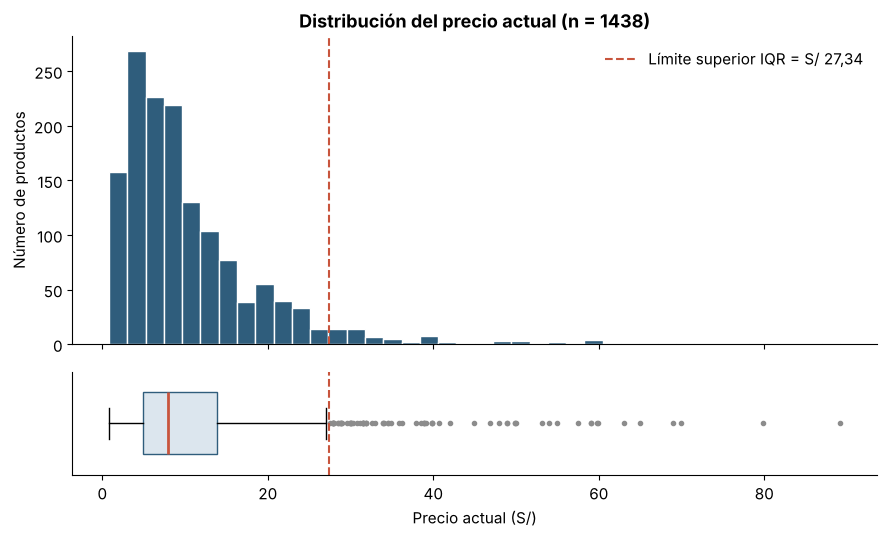

current_price: 74 outliers (5,15 %) sobre S/ 27,34; máximo S/ 89,20


In [22]:
def figura_outliers(serie, lim, titulo, xlabel, nombre, titulo_informe, pregunta, hallazgo, bins=40, unidad="S/"):
    # Histograma + boxplot horizontal con el límite superior IQR marcado (coma decimal en etiquetas)
    etiqueta_lim = f"S/ {nf(lim, 2)}" if unidad == "S/" else f"{nf(lim, 2)} %"
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1]})
    a1.hist(serie, bins=bins, color=AZUL, edgecolor="white")
    a1.axvline(lim, color=ROJO, ls="--", lw=1.5, label="Límite superior IQR = " + etiqueta_lim)
    a1.set_ylabel("Número de productos")
    a1.set_title(titulo)
    a1.legend(frameon=False)
    a2.boxplot(serie, orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#DCE6EE", color=AZUL), medianprops=dict(color=ROJO, lw=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor=GRIS))
    a2.axvline(lim, color=ROJO, ls="--", lw=1.5)
    a2.set_yticks([])
    a2.set_xlabel(xlabel)
    ejes_coma(a1); ejes_coma(a2, "x")
    plt.tight_layout()
    guardar_fig(fig, nombre, titulo_informe, pregunta, hallazgo, n=len(serie))
    plt.show()

t = tabla_iqr.loc["current_price"]
figura_outliers(df["current_price"], t["lim_sup"],
                f"Distribución del precio actual (n = {len(df)})", "Precio actual (S/)",
                "figA1_outliers_precio_actual.png", "Outliers del precio actual según el criterio IQR (n = 1438)",
                "Preprocesamiento: ¿existen precios actuales atípicos?",
                f"Límite superior S/ {nf(t['lim_sup'], 2)}; {int(t['n_outliers'])} outliers ({nf(t['pct_outliers'], 2)} %) conservados y marcados")
print(f"current_price: {int(t['n_outliers'])} outliers ({nf(t['pct_outliers'], 2)} %) sobre S/ {nf(t['lim_sup'], 2)}; "
      f"máximo S/ {nf(t['maximo'], 2)}")

**Conclusión.** El precio actual tiene una distribución con **cola larga a la derecha**: el 50 % central está entre S/ 4,90 y S/ 13,88 y **74 productos (5,15 %)** superan el límite superior IQR de **S/ 27,34**, hasta un máximo de S/ 89,20. No hay outliers por debajo (el límite inferior es negativo).

Figura guardada: reports/figures/figA2_outliers_precio_regular.png


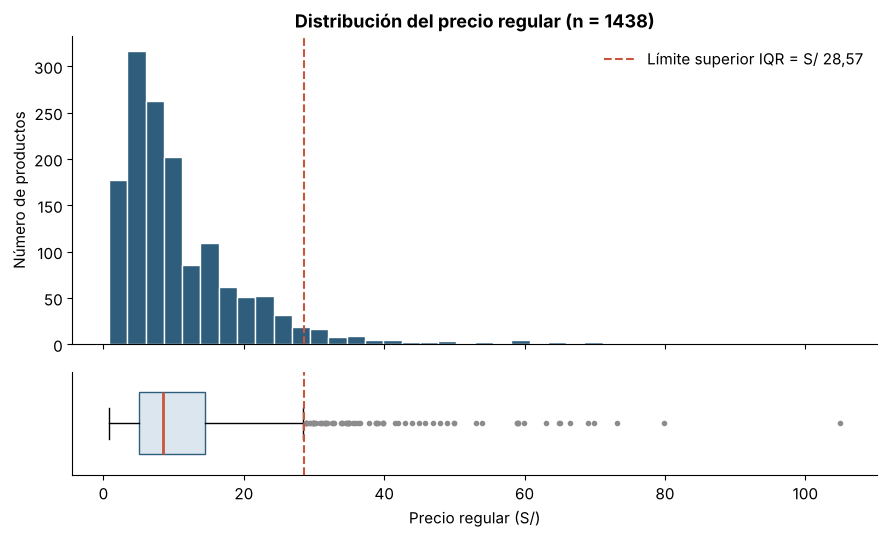

regular_price: 74 outliers (5,15 %) sobre S/ 28,57; máximo S/ 105,00


In [23]:
t = tabla_iqr.loc["regular_price"]
figura_outliers(df["regular_price"], t["lim_sup"],
                f"Distribución del precio regular (n = {len(df)})", "Precio regular (S/)",
                "figA2_outliers_precio_regular.png", "Outliers del precio regular según el criterio IQR (n = 1438)",
                "Preprocesamiento: ¿existen precios regulares atípicos?",
                f"Límite superior S/ {nf(t['lim_sup'], 2)}; {int(t['n_outliers'])} outliers; máximo S/ {nf(t['maximo'], 2)}")
print(f"regular_price: {int(t['n_outliers'])} outliers ({nf(t['pct_outliers'], 2)} %) sobre S/ {nf(t['lim_sup'], 2)}; "
      f"máximo S/ {nf(t['maximo'], 2)}")

**Conclusión.** El precio regular reproduce la misma forma asimétrica: **74 productos (5,15 %)** superan el límite IQR de **S/ 28,57**, con un máximo de **S/ 105,00**. Es esperable, porque en dos tercios de los productos el precio regular coincide con el actual.

Figura guardada: reports/figures/figA3_outliers_descuento_pct.png


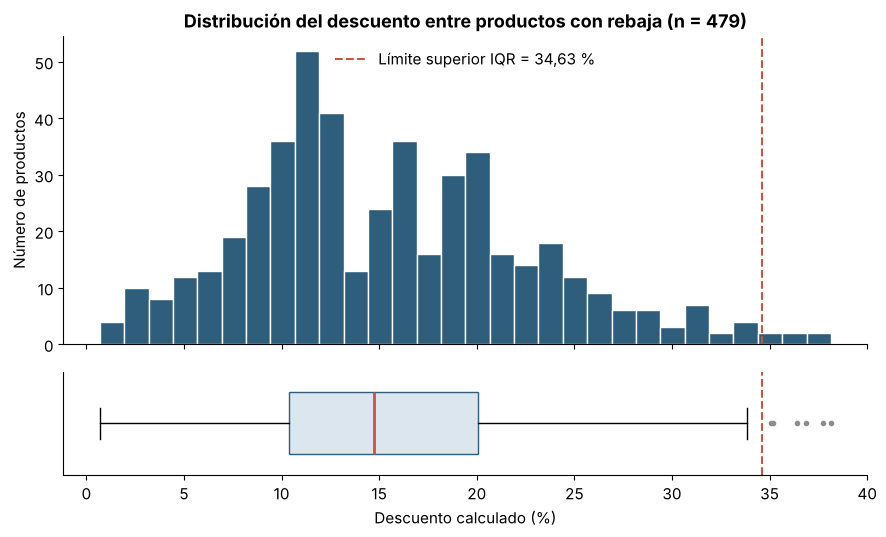

discount_pct: 6 de 479 outliers (1,25 %) sobre 34,63 %; máximo 38,14 %


In [24]:
t = tabla_iqr.loc["discount_pct (promocionados)"]
figura_outliers(df.loc[con_rebaja, "discount_pct"], t["lim_sup"],
                f"Distribución del descuento entre productos con rebaja (n = {int(con_rebaja.sum())})",
                "Descuento calculado (%)", "figA3_outliers_descuento_pct.png",
                "Outliers del descuento entre productos con rebaja según el criterio IQR (n = 479)",
                "Preprocesamiento: ¿existen descuentos atípicos?",
                f"Límite superior {nf(t['lim_sup'], 2)} %; {int(t['n_outliers'])} de {int(t['n_base'])} outliers "
                f"({nf(t['pct_outliers'], 2)} %); máximo {nf(t['maximo'], 2)} %", bins=30, unidad="%")
print(f"discount_pct: {int(t['n_outliers'])} de {int(t['n_base'])} outliers ({nf(t['pct_outliers'], 2)} %) sobre {nf(t['lim_sup'], 2)} %; "
      f"máximo {nf(t['maximo'], 2)} %")

**Conclusión.** Entre los 479 productos con rebaja, el descuento se concentra en un rango moderado: solo **6 de 479 (1,25 %)** superan el límite superior IQR de **34,63 %**, con un máximo de **38,14 %**. Ninguno queda por debajo del límite inferior.

In [25]:
# is_price_outlier: se compara con los límites EXACTOS de current_price (sin redondear)
lim_inf_precio = tabla_iqr.loc["current_price", "lim_inf"]
lim_sup_precio = tabla_iqr.loc["current_price", "lim_sup"]
df["is_price_outlier"] = ((df["current_price"] > lim_sup_precio) | (df["current_price"] < lim_inf_precio)).astype(int)
out_precio = (df.loc[df["is_price_outlier"] == 1, ["sku", "brand", "name", "category", "current_price", "regular_price"]]
                .sort_values("current_price", ascending=False))
print(f"Outliers de precio actual (> S/ {nf(lim_sup_precio, 2)}; límite exacto {lim_sup_precio}): {len(out_precio)}")
print("Precios en el intervalo de redondeo (límite exacto, límite redondeado]:",
      int(((df["current_price"] > lim_sup_precio) & (df["current_price"] <= round(lim_sup_precio, 2))).sum()))
print("\nCategoría de nivel 2 de los outliers:")
print(out_precio["category"].str.split(" / ").str[1].value_counts().to_string())
out_precio.to_csv(TAB_DIR / "outliers_precio_actual.csv", index=False, encoding="utf-8")
out_precio

Outliers de precio actual (> S/ 27,34; límite exacto 27.3375): 74
Precios en el intervalo de redondeo (límite exacto, límite redondeado]: 0

Categoría de nivel 2 de los outliers:
category
Aceite                          27
Chocolatería                    14
Salsas, Cremas y Condimentos     9
Azúcar y Endulzantes             8
Galletas y Golosinas             5
Snacks y Piqueos                 4
Arroz                            4
Conservas                        2
Packs Abarrotes                  1


,sku,brand,name,category,current_price,regular_price
43,10216187,LAKANTO,Endulzante Natural LAKANTO Sweetener Golden Do...,Abarrotes / Azúcar y Endulzantes / Otros Endul...,89.2,105.0
587,54579,VALDEPORRES,Aceite de Oliva VALDEPORRES Gran Selección Bot...,Abarrotes / Aceite / Aceite de Oliva,79.9,79.9
223,10708655,BELL'S,Aceite de Oliva BELL'S Extra Virgen Botella 2L,Abarrotes / Aceite / Aceite de Oliva,69.9,69.9
757,10305534,FLORIDA,Filete de Atún FLORIDA en Agua Paquete 12un,Abarrotes / Conservas / Pescados en Conserva,69.0,69.0
1212,12067976,NESTLÉ,Chocolate NESTLÉ Sublime Sonrisa Display 20un,Abarrotes / Chocolatería / Chocolates y Lentejas,65.0,65.0
...,...,...,...,...,...,...
226,10573292,BELL'S,Aceite de Oliva Extra Virgen BELL'S Botella 500ml,Abarrotes / Aceite / Aceite de Oliva,27.9,27.9
1070,12346646,VIA,Endulzante Tagatosa Líquida VIA Pote 100ml,Abarrotes / Azúcar y Endulzantes / Otros Endul...,27.9,27.9
738,10765067,NUTRA STEVIA,Endulzante Líquido con Yacón NUTRA STEVIA Bote...,Abarrotes / Azúcar y Endulzantes / Otros Endul...,27.9,27.9
1400,11473597,LKK,Teriyaki LKK Botella 250g,"Abarrotes / Salsas, Cremas y Condimentos / Sal...",27.9,27.9


In [26]:
# Outliers de descuento entre promocionados
lim_sup_desc = tabla_iqr.loc["discount_pct (promocionados)", "lim_sup"]
out_desc = (df.loc[con_rebaja & (df["discount_pct"] > lim_sup_desc),
                   ["sku", "brand", "name", "category", "current_price", "regular_price", "discount_pct"]]
              .sort_values("discount_pct", ascending=False))
print(f"Outliers de descuento (> {nf(lim_sup_desc, 2)} %): {len(out_desc)}")
out_desc

Outliers de descuento (> 34,63 %): 6


,sku,brand,name,category,current_price,regular_price,discount_pct
158,19842,ONZA,Sal de Maras Fina ONZA Doypack 500g,"Abarrotes / Salsas, Cremas y Condimentos / Sal...",6.0,9.7,38.14
788,10020907,MUTTI,Passata de Tomate MUTTI Frasco 400g,"Abarrotes / Fideos, Pastas y Salsas / Salsas d...",9.9,15.9,37.74
1048,12400510,TAKIS,Tortillas de Maíz TAKIS Buckin' Ranch Bolsa 190g,Abarrotes / Snacks y Piqueos / Maíz,6.0,9.5,36.84
1085,12338940,BON O BON,Bombones de Chocolate BON O BON Supreme Caja 144g,Abarrotes / Chocolatería / Bombones,15.9,25.0,36.40
1061,12384045,SPLENDA,Endulzante SPLENDA Stevia Doypack 175g,Abarrotes / Azúcar y Endulzantes / Otros Endul...,26.9,41.5,35.18
821,41859,WALIBI,Mayonesa WALIBI Doypack 1Kg,"Abarrotes / Salsas, Cremas y Condimentos / May...",13.9,21.4,35.05


In [27]:
r2 = lambda x: float(np.round(float(x), 2))   # mismo redondeo que DataFrame.round(2)
M["iqr"] = {k: {"Q1": r2(r.Q1), "Q3": r2(r.Q3), "IQR": r2(r.IQR),
                "lim_inf": r2(r.lim_inf), "lim_sup": r2(r.lim_sup),
                "lim_sup_exacto": round(float(r.lim_sup), 4),
                "n_outliers": int(r.n_outliers), "n_base": int(r.n_base),
                "pct_outliers": float(r.pct_outliers), "maximo": r2(r.maximo)}
            for k, r in tabla_iqr.iterrows()}
M["n_outliers_precio_actual"] = int(df["is_price_outlier"].sum())
M["n_outliers_descuento"] = int(len(out_desc))
M["outliers_precio_por_grupo_clean"] = out_precio["category"].str.split(" / ").str[1].value_counts().to_dict()
print(json.dumps(M["iqr"], indent=1, ensure_ascii=False))

{
 "current_price": {
  "Q1": 4.9,
  "Q3": 13.88,
  "IQR": 8.98,
  "lim_inf": -8.56,
  "lim_sup": 27.34,
  "lim_sup_exacto": 27.3375,
  "n_outliers": 74,
  "n_base": 1438,
  "pct_outliers": 5.15,
  "maximo": 89.2
 },
 "regular_price": {
  "Q1": 5.12,
  "Q3": 14.5,
  "IQR": 9.38,
  "lim_inf": -8.94,
  "lim_sup": 28.57,
  "lim_sup_exacto": 28.5663,
  "n_outliers": 74,
  "n_base": 1438,
  "pct_outliers": 5.15,
  "maximo": 105.0
 },
 "discount_pct (promocionados)": {
  "Q1": 10.38,
  "Q3": 20.08,
  "IQR": 9.7,
  "lim_inf": -4.17,
  "lim_sup": 34.63,
  "lim_sup_exacto": 34.63,
  "n_outliers": 6,
  "n_base": 479,
  "pct_outliers": 1.25,
  "maximo": 38.14
 }
}


**Decisión: conservar los outliers y marcarlos.** Los precios atípicos corresponden a productos cuya naturaleza justifica un precio alto (aceites de oliva, endulzantes como LAKANTO, packs y *displays* con varias unidades, presentaciones grandes). No son errores de captura: los precios son positivos, `current_price ≤ regular_price` y los productos existen en el catálogo. Eliminarlos sesgaría el análisis hacia productos baratos. Por ello se crea `is_price_outlier` (1 = precio actual fuera de los límites IQR), que permite reportar estadísticos robustos (mediana) o filtrar si un análisis lo requiere. Los 6 descuentos atípicos también son coherentes con sus precios y se conservan, sin flag propio (se listan en la tabla anterior y en las anomalías del notebook 03). **`is_price_outlier` se define solo sobre `current_price`** porque es el precio que se analiza; el precio regular tiene el mismo número de outliers (74) y un flag adicional sería redundante.

## 6. Transformación de datos

Se aplican transformaciones de formato y estructura: normalización textual de marca, separación jerárquica de la categoría, tipificación de `stock` y reemplazo del descuento inválido por el reconstruido.

In [28]:
# 6.1 Normalización textual de brand: strip, colapsar espacios, mayúsculas y unificar variantes
df["brand_original"] = df["brand"]
df["brand"] = df["brand"].str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
MAPA_VARIANTES = {"CASAVERDE": "CASA VERDE", "LAYS": "LAY'S", "NESTLE": "NESTLÉ"}
MAPA_MARCAS = {**MAPA_VARIANTES, **MAPA_APOSTROFO}
df["brand"] = df["brand"].replace(MAPA_MARCAS)
n_mod_var = int(df["brand_original"].isin(MAPA_VARIANTES.keys()).sum())
n_mod_apo = int(df["brand_original"].isin(MAPA_APOSTROFO.keys()).sum())
print("Marcas únicas antes:", df["brand_original"].nunique(), "| después:", df["brand"].nunique())
print("Registros modificados:", int((df["brand"] != df["brand_original"]).sum()),
      f"(variantes unificadas: {n_mod_var}; apóstrofo reconstruido: {n_mod_apo})")
M["marcas_unicas_raw"] = int(df["brand_original"].nunique())
M["marcas_unicas_normalizadas"] = int(df["brand"].nunique())
M["marcas_unificadas"] = MAPA_VARIANTES
M["marcas_apostrofo_reconstruido"] = {b: {"nueva": v, "n": int((df["brand_original"] == b).sum())} for b, v in MAPA_APOSTROFO.items()}
M["marcas_registros_modificados"] = {"variantes": n_mod_var, "apostrofo": n_mod_apo}
M["submarcas_conservadas"] = submarcas.to_dict("records")

Marcas únicas antes: 275 | después: 272
Registros modificados: 27 (variantes unificadas: 3; apóstrofo reconstruido: 24)


In [29]:
# 6.1b Colapsar dobles espacios internos en name y presentation
for c in ["name", "presentation"]:
    antes = int(df[c].str.contains(r"\s{2,}").sum())
    df[c] = df[c].str.strip().str.replace(r"\s+", " ", regex=True)
    print(f"{c}: registros con dobles espacios corregidos = {antes}")

# 6.2 Parsing jerárquico de category
partes = df["category"].str.split(" / ")
df["category_level1"] = partes.str[0]
df["category_group"] = partes.str[1]
df["subcategory"] = partes.str[2].fillna(partes.str[1])  # si no hay nivel 3 se repite el nivel 2
print("category_level1:", df["category_level1"].nunique(), "| category_group:", df["category_group"].nunique(),
      "| subcategory:", df["subcategory"].nunique())
df[["category", "category_level1", "category_group", "subcategory"]].drop_duplicates().sample(6, random_state=1)

# Conteos en el dataset limpio (1438) frente al dataset analítico (solo Abarrotes/Packs)
alcance = df["category_level1"].isin(["Abarrotes", "Packs"])
conteos = pd.DataFrame({
    "dataset_limpio": [len(df), df["brand"].nunique(), df["category_group"].nunique(), df["subcategory"].nunique()],
    "dataset_analitico": [int(alcance.sum()), df.loc[alcance, "brand"].nunique(),
                          df.loc[alcance, "category_group"].nunique(), df.loc[alcance, "subcategory"].nunique()],
}, index=["registros", "marcas", "category_group", "subcategory"])
fuera = df.loc[~alcance, ["sku", "brand", "name", "category_group", "subcategory"]]
print("\nMarcas/grupos/subcategorías que solo aparecen en el registro fuera de alcance:")
print("  marca:", sorted(set(fuera["brand"]) - set(df.loc[alcance, "brand"])),
      "| grupo:", sorted(set(fuera["category_group"]) - set(df.loc[alcance, "category_group"])),
      "| subcategoría:", sorted(set(fuera["subcategory"]) - set(df.loc[alcance, "subcategory"])))
conteos

name: registros con dobles espacios corregidos = 5
presentation: registros con dobles espacios corregidos = 8
category_level1: 3 | category_group: 13 | subcategory: 71

Marcas/grupos/subcategorías que solo aparecen en el registro fuera de alcance:
  marca: ['SAN SEN'] | grupo: ['Verduras'] | subcategoría: ['Verduras Orientales']


,dataset_limpio,dataset_analitico
registros,1438,1437
marcas,272,271
category_group,13,12
subcategory,71,70


In [30]:
# 6.3 stock a booleano explícito (ya viene como bool; se asegura el tipo)
df["stock"] = df["stock"].astype(str).str.lower().map({"true": True, "false": False}).astype(bool)

# 6.4 Descuento: el original se conserva solo como trazabilidad y se reemplaza por el reconstruido
df = df.rename(columns={"discount": "discount_original"})
print(df[["stock", "discount_original", "discount_pct"]].dtypes)

stock                   bool
discount_original    float64
discount_pct         float64
dtype: object


**Conclusión.** La normalización reduce las marcas de **275 a 272** al unificar 3 registros con variantes de escritura, y corrige el texto de otros 24 registros de 4 marcas con apóstrofo perdido (sin cambiar el conteo de marcas). Se colapsan los dobles espacios de 5 nombres y 8 presentaciones. La categoría queda separada en tres niveles reutilizables para agrupar.

> **Nota sobre las bases de conteo.** Este notebook describe el **dataset limpio (1438 registros)**: 272 marcas, 13 grupos y 71 subcategorías. El **dataset analítico (1437)** tiene **271 marcas, 12 grupos y 70 subcategorías**, porque la marca `SAN SEN`, el grupo *Verduras* y la subcategoría *Verduras Orientales* solo aparecen en el registro fuera de alcance. Las cifras analíticas oficiales del informe son las del dataset analítico.

El descuento original se renombra `discount_original` y se mantiene solo en el dataset limpio como evidencia del problema de captura.

## 7. Feature Engineering

Cada variable derivada se documenta con su **fórmula**, su **significado**, el **motivo** de su creación y el **análisis que habilita** en el notebook `03_analysis.ipynb`.

| Variable | Fórmula | Significado | Motivo | Análisis que habilita |
|---|---|---|---|---|
| `has_discount` | 1 si `regular_price − current_price > 0,005` | El producto muestra rebaja en el snapshot | El `discount` original es inválido; se necesita un indicador binario confiable | Tasa promocional (`promo_rate`) global, por marca y por categoría |
| `discount_amount` | `regular_price − current_price` (S/) | Ahorro absoluto por unidad | Complementa al % (un 10 % en un aceite no equivale a un 10 % en un caramelo) | Magnitud del ahorro en soles, anomalías |
| `discount_pct` | `(regular_price − current_price) / regular_price × 100` (2 dec.) | Descuento relativo observado | Reemplaza al descuento inválido | Magnitud de descuentos, relación precio–descuento |
| `promotion_intensity` | Sin descuento (0) / Bajo (0, 10] / Medio (10, 20] / Alto (> 20) | Nivel de profundidad de la rebaja | Facilita comparar segmentos con categorías legibles | Distribución de intensidad, intensidad por grupo |
| `category_level1`, `category_group`, `subcategory` | Separación de `category` por “ / ” | Jerarquía del catálogo | `category` mezcla tres niveles en un texto | Segmentación por grupo y subcategoría |
| `presentation_imputed` | 1 si `presentation` era nulo y se derivó de `name` | Origen del dato | Trazabilidad de la imputación; el faltante no es aleatorio (4.1) | Sensibilidad de `promo_rate` a los registros imputados |
| `content_qty`, `content_unit` | Cantidad y unidad extraídas de `presentation` y llevadas a g, ml o unidades (kg × 1000, L × 1000, oz × 28,3495; el multiplicador “x N” se aplica) | Contenido total publicado del producto | Los precios absolutos mezclan tamaños distintos | Base de `unit_price` |
| `has_multiplier` | 1 si `presentation` incluye un multiplicador “x N” | El contenido se calculó multiplicando | Señalar los contenidos derivados de una operación | Control de calidad de `unit_price` |
| `content_validated` | 1 si el contenido de `presentation` coincide con el que figura en `name`, o si `presentation` se imputó desde `name` | Contenido confirmado por dos fuentes de la misma tarjeta | Algunas presentaciones publicadas contradicen el nombre (p. ej. “Lata 140un” en un atún de 140 g) | Filtro de las comparaciones de `unit_price` |
| `unit_price` | `current_price / content_qty` × 1000 (S/ por kg o L) o × 1 (S/ por unidad) | Precio publicado normalizado por contenido | Permite comparar precios dentro de una subcategoría sin el efecto del tamaño | Precio por kg/L dentro de subcategorías; BELL'S vs. resto |
| `is_price_outlier` | 1 si `current_price` está fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR] (límites exactos) | Precio atípico | Se conservan outliers pero se identifican | Anomalías, estadísticos robustos |
| `is_pack` | 1 si `category_level1 = "Packs"` o `name` empieza con “Pack” | Producto agrupado (varias unidades/productos) | Distinguir los packs ubicados fuera de la categoría Packs | Contraste *Packs Abarrotes* vs. packs en otras categorías (casi redundante con `category_group`; ver 7.2) |
| `in_scope` | `category_level1` ∈ {Abarrotes, Packs} | Pertenece al alcance del proyecto | Excluir el producto de Frutas y Verduras | Definición del dataset analítico |

In [31]:
# has_discount, discount_amount y discount_pct
df["discount_amount"] = (df["regular_price"] - df["current_price"]).round(2)
df["has_discount"] = (df["discount_amount"] > TOL).astype(int)
df.loc[df["has_discount"] == 0, "discount_amount"] = 0.0
df["discount_pct"] = df["discount_pct"].where(df["has_discount"] == 1, 0.0).round(2)
print("Productos con rebaja:", int(df["has_discount"].sum()), f"({df['has_discount'].mean()*100:.1f} %)")
df.loc[df["has_discount"] == 1, ["discount_amount", "discount_pct"]].describe().round(2)

Productos con rebaja: 479 (33.3 %)


,discount_amount,discount_pct
count,479.00,479.00
mean,1.89,15.45
std,2.04,7.25
min,0.10,0.69
25%,0.60,10.38
50%,1.10,14.71
75%,2.40,20.08
max,15.80,38.14


### 7.1 Justificación de los cortes de `promotion_intensity`

Antes de fijar los cortes se revisan los cuartiles reales de `discount_pct` entre los productos con rebaja. Si Q1 y Q3 están cerca de 10 % y 20 %, los cortes redondos 10/20 son a la vez **coherentes con los datos** (separan aproximadamente el cuarto inferior, la mitad central y el cuarto superior) y **legibles comercialmente**.

In [32]:
promo = df.loc[df["has_discount"] == 1, "discount_pct"]
cuartiles = promo.quantile([0.25, 0.50, 0.75]).round(2)
print("Cuartiles de discount_pct entre promocionados:", cuartiles.to_dict())
M["discount_pct_promocionados_cuartiles"] = {str(k): float(v) for k, v in cuartiles.items()}

CORTES = [-np.inf, 0, 10, 20, np.inf]
ETIQUETAS = ["Sin descuento", "Bajo", "Medio", "Alto"]
df["promotion_intensity"] = pd.cut(df["discount_pct"], bins=CORTES, labels=ETIQUETAS, right=True).astype(str)
dist_int = df["promotion_intensity"].value_counts().reindex(ETIQUETAS)
print("\nDistribución de promotion_intensity (1438 registros):")
print(pd.DataFrame({"n": dist_int, "pct": (dist_int / len(df) * 100).round(1)}).to_string())
print("\nReparto entre promocionados (%):",
      (dist_int.drop("Sin descuento") / dist_int.drop("Sin descuento").sum() * 100).round(1).to_dict())

Cuartiles de discount_pct entre promocionados: {0.25: 10.38, 0.5: 14.71, 0.75: 20.08}

Distribución de promotion_intensity (1438 registros):
                       n   pct
promotion_intensity           
Sin descuento        959  66.7
Bajo                 109   7.6
Medio                249  17.3
Alto                 121   8.4

Reparto entre promocionados (%): {'Bajo': 22.8, 'Medio': 52.0, 'Alto': 25.3}


In [33]:
# Sensibilidad de los cortes de promotion_intensity: valores en los bordes y cortes alternativos
print("Descuentos exactamente en 10,00 %:", int((promo == 10).sum()),
      "| exactamente en 20,00 %:", int((promo == 20).sum()),
      "| entre 19,5 % y 20,5 %:", int(promo.between(19.5, 20.5).sum()))
es_pack_promo = df.loc[promo.index, "category"].str.startswith("Packs")
q1e, q3e = promo.quantile(0.25), promo.quantile(0.75)
NIV = ["Bajo", "Medio", "Alto"]
alternativas = {
    "10/20, intervalos (a, b] (elegido)": pd.cut(promo, [0, 10, 20, np.inf], labels=NIV, right=True),
    "10/20, intervalos [a, b)": pd.cut(promo, [0, 10, 20, np.inf], labels=NIV, right=False),
    f"Cuartiles exactos {nf(q1e, 2)}/{nf(q3e, 2)}, (a, b]": pd.cut(promo, [0, q1e, q3e, np.inf], labels=NIV, right=True),
}
filas = []
for nombre, clase in alternativas.items():
    reparto = clase.value_counts(normalize=True).reindex(NIV) * 100
    filas.append({"cortes": nombre, **{f"pct_{k}": round(v, 1) for k, v in reparto.items()},
                  "nivel_predominante": reparto.idxmax(),
                  "packs_pct_alto": round((clase[es_pack_promo] == "Alto").mean() * 100, 1)})
sens_cortes = pd.DataFrame(filas).set_index("cortes")
M["sensibilidad_cortes_intensidad"] = {
    "n_exacto_10": int((promo == 10).sum()), "n_exacto_20": int((promo == 20).sum()),
    "n_entre_19_5_y_20_5": int(promo.between(19.5, 20.5).sum()),
    "alternativas": sens_cortes.reset_index().to_dict("records")}
sens_cortes

Descuentos exactamente en 10,00 %: 11 | exactamente en 20,00 %: 11 | entre 19,5 % y 20,5 %: 31


,pct_Bajo,pct_Medio,pct_Alto,nivel_predominante,packs_pct_alto
cortes,,,,,
"10/20, intervalos (a, b] (elegido)",22.8,52.0,25.3,Medio,43.3
"10/20, intervalos [a, b)",20.5,52.0,27.6,Medio,50.0
"Cuartiles exactos 10,38/20,08, (a, b]",25.1,50.1,24.8,Medio,43.3


**Conclusión.** Entre los 479 promocionados, Q1 ≈ 10,4 %, la mediana ≈ 14,7 % y Q3 ≈ 20,1 %. Los cortes 10 % y 20 % coinciden prácticamente con Q1 y Q3, de modo que *Bajo* ≈ cuarto inferior, *Medio* ≈ mitad central y *Alto* ≈ cuarto superior.

**Sensibilidad en los bordes.** Hay 11 descuentos de exactamente 10,00 % y 11 de exactamente 20,00 % (31 entre 19,5 % y 20,5 %): son rebajas “redondas”. Con intervalos cerrados por la derecha (`right=True`), un 10 % exacto es *Bajo* y un 20 % exacto es *Medio*; la justificación es que una rebaja redonda de 20 % es la promoción estándar y se agrupa con el nivel central, mientras que *Alto* queda reservado para rebajas que **superan** ese estándar. La tabla muestra que las conclusiones no dependen de esta elección: con intervalos cerrados por la izquierda o con los cuartiles exactos (10,38 / 20,08), *Medio* sigue siendo el nivel predominante y *Packs* conserva una proporción de *Alto* de entre 43,3 % (cortes elegidos y cuartiles exactos) y 50,0 % (intervalos cerrados por la izquierda), muy por encima del 25,3 % del conjunto. Por legibilidad se mantienen los cortes redondos 10/20.

> **Nota.** El conteo de 959 productos *Sin descuento* corresponde al dataset limpio (1438); en el dataset analítico (1437) son 958, porque el registro fuera de alcance no tiene rebaja. Las cifras oficiales del informe son las del dataset analítico.

In [34]:
# is_pack e in_scope
df["is_pack"] = ((df["category_level1"] == "Packs") | df["name"].str.startswith("Pack")).astype(int)
df["in_scope"] = df["category_level1"].isin(["Abarrotes", "Packs"])
packs_fuera = df.loc[(df["is_pack"] == 1) & (df["category_level1"] != "Packs"),
                     ["sku", "name", "category_group", "current_price", "has_discount"]]
print("is_pack = 1:", int(df["is_pack"].sum()),
      "| por categoría Packs:", int((df["category_level1"] == "Packs").sum()),
      "| por nombre 'Pack…' fuera de la categoría Packs:", len(packs_fuera))
print("in_scope = True:", int(df["in_scope"].sum()), "| fuera de alcance:", int((~df["in_scope"]).sum()))
M["n_is_pack"] = int(df["is_pack"].sum())
M["n_is_pack_fuera_categoria_packs"] = int(len(packs_fuera))
M["n_in_scope"] = int(df["in_scope"].sum())
M["n_promocionados_total"] = int(df["has_discount"].sum())
packs_fuera

is_pack = 1: 64 | por categoría Packs: 60 | por nombre 'Pack…' fuera de la categoría Packs: 4
in_scope = True: 1437 | fuera de alcance: 1


,sku,name,category_group,current_price,has_discount
230,10457717,Pack Salsa de Tomate POMAROLA Bolsa 870g,"Fideos, Pastas y Salsas",10.5,0
656,12400501,Pack EL OLIVAR Aceite de Oliva Extra Virgen Bo...,Aceite,39.9,0
791,81697,Pack B&D Ketchup Frasco 425g + Mostaza Frasco ...,"Salsas, Cremas y Condimentos",11.2,0
1207,12090070,Pack Fiesta COSTA Jajajalloween Bolsa 266g,Galletas y Golosinas,14.5,0


### 7.2 Decisión sobre `is_pack`

`is_pack` marca 64 productos: los 60 de la categoría *Packs* y 4 productos agrupados ubicados en otras categorías cuyo nombre empieza con “Pack”. Es **casi redundante** con `category_group = "Packs Abarrotes"` (coinciden en 60 de 64 casos), pero se conserva porque esos 4 casos permiten contrastar el **formato** pack con la **categoría** Packs del listado. Ninguno de los 4 tiene rebaja (0/4), lo que en el notebook 03 indica que la alta frecuencia de rebajas de los packs se asocia a la categoría *Packs Abarrotes* y no al formato en sí. `in_scope` deja **1437** registros dentro del alcance.

### 7.3 Contenido (`content_qty`, `content_unit`) y precio unitario (`unit_price`)

El precio absoluto mezcla tamaños: un aceite de 1 L y uno de 200 ml no son comparables. Se extrae de `presentation` la cantidad y la unidad (el mismo patrón de la imputación), se llevan a una unidad base (g, ml o unidades) y se aplica el multiplicador “x N” cuando existe (p. ej., “Paquete 6un x 2un” = 12 unidades; “Bolsa 190g x 2un” = 380 g; “Caja 10un x 17.1g” = 171 g). Con ello `unit_price` expresa el precio publicado en **S/ por kg**, **S/ por litro** o **S/ por unidad**. Se valida comparando el contenido de `presentation` con el que figura en el nombre.

In [35]:
patron_cont = re.compile(
    r"(?P<cant>\d+(?:[.,]\d+)?)\s*(?P<unidad>kg|gr|g|ml|l|un|cc|oz)g?\b"
    r"(?:\s*x\s*(?P<mult>\d+(?:[.,]\d+)?)\s*(?P<unidad_mult>kg|gr|g|ml|l|un)?)?\s*$",
    flags=re.IGNORECASE)
A_BASE = {"kg": ("g", 1000), "gr": ("g", 1), "g": ("g", 1), "oz": ("g", 28.3495),
          "l": ("ml", 1000), "ml": ("ml", 1), "cc": ("ml", 1), "un": ("un", 1)}

def contenido(texto):
    # Devuelve (cantidad total en unidad base, unidad base, tiene_multiplicador) a partir de "Envase cant+unidad [x N]"
    m = patron_cont.search(texto) if isinstance(texto, str) else None
    if m is None:
        return (np.nan, np.nan, 0)
    unidad, factor = A_BASE[m.group("unidad").lower()]
    cant = float(m.group("cant").replace(",", ".")) * factor
    if not m.group("mult"):
        return (round(cant, 2), unidad, 0)
    k = float(m.group("mult").replace(",", "."))
    u_mult = (m.group("unidad_mult") or "un").lower()
    if u_mult == "un":          # "6un x 2un": 2 envases de 6 unidades; "190g x 2un": 2 envases de 190 g
        cant *= k
    else:                       # "10un x 17.1g": 10 unidades de 17,1 g -> contenido total en g
        unidad, factor = A_BASE[u_mult]
        cant = cant * k * factor
    return (round(cant, 2), unidad, 1)

cont = pd.DataFrame(df["presentation"].map(contenido).tolist(), index=df.index,
                    columns=["content_qty", "content_unit", "has_multiplier"])
df[["content_qty", "content_unit", "has_multiplier"]] = cont
ESCALA = {"g": 1000, "ml": 1000, "un": 1}                 # S/ por kg, por litro o por unidad
BASE_UNIT_PRICE = {"g": "S/ por kg", "ml": "S/ por litro", "un": "S/ por unidad"}
df["unit_price"] = (df["current_price"] / df["content_qty"] * df["content_unit"].map(ESCALA)).round(2)
print("Registros sin contenido interpretable:", int(df["content_qty"].isna().sum()))
print("Con multiplicador:", int(df["has_multiplier"].sum()))
print("\nUnidad base del contenido:\n", df["content_unit"].value_counts().to_string())

# Validación: contenido publicado en presentation vs. contenido que figura en el nombre (solo no imputados)
desde_nombre = pd.DataFrame(df["name"].map(lambda s: contenido(presentacion_desde_nombre(s))).tolist(),
                            index=df.index, columns=["qty_name", "unit_name", "mult_name"])
base_val = (df["presentation_imputed"] == 0) & desde_nombre["qty_name"].notna()
coincide_cont = ((desde_nombre.loc[base_val, "qty_name"] == df.loc[base_val, "content_qty"]) &
                 (desde_nombre.loc[base_val, "unit_name"] == df.loc[base_val, "content_unit"]))
print(f"\nValidación: en {int(base_val.sum())} registros no imputados con contenido en el nombre, el contenido "
      f"coincide en {int(coincide_cont.sum())} ({nf(coincide_cont.mean() * 100)} %).")
print("Ejemplos de discrepancia (se respeta el valor publicado en presentation):")
display(df.loc[coincide_cont[~coincide_cont].index, ["sku", "name", "presentation", "content_qty", "content_unit"]].head(5))

# content_validated: contenido confirmado por el nombre (o presentación imputada desde el nombre)
df["content_validated"] = ((df["presentation_imputed"] == 1) | (base_val & coincide_cont.reindex(df.index, fill_value=False))).astype(int)
print("content_validated = 1:", int(df["content_validated"].sum()), "de", len(df),
      "| discrepancias:", int((base_val & ~coincide_cont.reindex(df.index, fill_value=False)).sum()),
      "| no imputados sin contenido en el nombre:", int(((df["presentation_imputed"] == 0) & ~base_val).sum()))

resumen_up = df.groupby("content_unit")["unit_price"].describe()[["count", "50%", "min", "max"]].round(2)
resumen_up.index = resumen_up.index.map(lambda u: f"{u} ({BASE_UNIT_PRICE[u]})")
M["contenido"] = {"n_sin_contenido": int(df["content_qty"].isna().sum()), "n_con_multiplicador": int(df["has_multiplier"].sum()),
                  "unidades": {k: int(v) for k, v in df["content_unit"].value_counts().items()},
                  "validacion_n_base": int(base_val.sum()), "validacion_n_coincide": int(coincide_cont.sum()),
                  "validacion_pct_coincide": round(coincide_cont.mean() * 100, 2),
                  "n_content_validated": int(df["content_validated"].sum()),
                  "unit_price_base": BASE_UNIT_PRICE}
resumen_up

Registros sin contenido interpretable: 0
Con multiplicador: 18

Unidad base del contenido:
 content_unit
g     1122
un     188
ml     128

Validación: en 1277 registros no imputados con contenido en el nombre, el contenido coincide en 1189 (93,1 %).
Ejemplos de discrepancia (se respeta el valor publicado en presentation):


,sku,name,presentation,content_qty,content_unit
2,10322535,Galletas FIELD Charada Paquete 6un,Paquete 226.8g,226.8,g
6,10918188,Galletas Saladas CLUB SOCIAL sabor Original Pa...,Bolsa 144g,144.0,g
9,10322536,Galletas FIELD Coronita Paquete 6un,Paquete 216g,216.0,g
10,1163,Galletas FIELD Vainilla Paquete 6un,Paquete 222g,222.0,g
57,10457684,Galletas OREO Original Paquete 12un,Paquete 432g,432.0,g


content_validated = 1: 1327 de 1438 | discrepancias: 88 | no imputados sin contenido en el nombre: 23


,count,50%,min,max
content_unit,,,,
g (S/ por kg),1122.0,39.53,1.90,2590.00
ml (S/ por litro),128.0,41.30,2.89,279.00
un (S/ por unidad),188.0,0.82,0.04,19.95


**Conclusión.** Las 1438 presentaciones tienen un contenido interpretable (18 con multiplicador): 1122 se expresan en peso, 188 en unidades y 128 en volumen. En los 1277 registros no imputados cuyo nombre también indica el contenido, ambos coinciden en 1189 (93,1 %). Las 88 discrepancias son de dos tipos: la tarjeta describe la unidad de referencia en lugar del envase comercial (p. ej., nombre “Paquete 6un” y presentación “Paquete 226.8g”, ambos plausibles) o la presentación publicada es claramente errónea (p. ej., “Lata 140un” en un atún de 140 g). Como no hay una regla segura para elegir, se respeta el valor publicado y se crea `content_validated`: las comparaciones de `unit_price` del notebook 03 usan solo los **1327** registros con contenido confirmado. Además, como `unit_price` usa unidades distintas (kg, litro, unidad), **solo se compara dentro de una misma subcategoría y unidad**. Es un precio publicado normalizado; no mide competitividad ni preferencia del consumidor.

## 8. Reducción de datos

La reducción es **de dimensionalidad por columnas** (no se eliminan filas, salvo el registro fuera de alcance en el dataset analítico). Criterios: varianza cero, faltantes masivos sin valor analítico, invalidez y redundancia con variables derivadas.

In [36]:
COLS_FINAL = ["sku", "name", "brand", "category_level1", "category_group", "subcategory",
              "presentation", "presentation_imputed", "content_qty", "content_unit", "has_multiplier",
              "content_validated", "current_price", "regular_price", "unit_price",
              "has_discount", "discount_amount", "discount_pct", "promotion_intensity",
              "is_price_outlier", "is_pack"]

decision_cols = pd.DataFrame([
    ("sku", "Se conserva", "Identificador único del producto (clave)"),
    ("brand", "Se conserva (normalizada)", "Segmentación por marca"),
    ("name", "Se conserva", "Descripción; base de la imputación y de is_pack"),
    ("category", "Se reemplaza", "Separada en category_level1 / category_group / subcategory"),
    ("seller", "Se excluye", "Varianza cero: 'plaza vea' en el 100 %"),
    ("stock", "Se excluye", "Varianza cero: True en el 100 %"),
    ("presentation", "Se conserva (imputada)", "Envase y tamaño; flag presentation_imputed; base de content_qty y unit_price"),
    ("current_price", "Se conserva", "Variable analítica central (S/)"),
    ("regular_price", "Se conserva", "Variable analítica central (S/)"),
    ("discount", "Se excluye", "Inválida: 0 en el 100 % pese a 479 rebajas; reemplazada por discount_pct"),
    ("product_url", "Solo dataset limpio", "Trazabilidad; sin valor analítico (sku ya identifica)"),
    ("image_url", "Solo dataset limpio", "94,5 % nulos por lazy-loading; sin valor analítico"),
], columns=["columna_raw", "decision", "justificacion"])
display(Markdown(md_table(decision_cols)))
M["decision_columnas"] = decision_cols.to_dict("records")

| columna_raw | decision | justificacion |
|---|---|---|
| sku | Se conserva | Identificador único del producto (clave) |
| brand | Se conserva (normalizada) | Segmentación por marca |
| name | Se conserva | Descripción; base de la imputación y de is_pack |
| category | Se reemplaza | Separada en category_level1 / category_group / subcategory |
| seller | Se excluye | Varianza cero: 'plaza vea' en el 100 % |
| stock | Se excluye | Varianza cero: True en el 100 % |
| presentation | Se conserva (imputada) | Envase y tamaño; flag presentation_imputed; base de content_qty y unit_price |
| current_price | Se conserva | Variable analítica central (S/) |
| regular_price | Se conserva | Variable analítica central (S/) |
| discount | Se excluye | Inválida: 0 en el 100 % pese a 479 rebajas; reemplazada por discount_pct |
| product_url | Solo dataset limpio | Trazabilidad; sin valor analítico (sku ya identifica) |
| image_url | Solo dataset limpio | 94,5 % nulos por lazy-loading; sin valor analítico |

In [37]:
clean = df[["sku", "brand", "brand_original", "name", "category", "category_level1", "category_group",
            "subcategory", "seller", "stock", "presentation", "presentation_imputed",
            "content_qty", "content_unit", "has_multiplier", "content_validated",
            "current_price", "regular_price", "unit_price", "discount_original", "has_discount", "discount_amount",
            "discount_pct", "promotion_intensity", "is_price_outlier", "is_pack", "in_scope",
            "product_url", "image_url"]].copy()
final = clean.loc[clean["in_scope"], COLS_FINAL].reset_index(drop=True)

antes_despues = pd.DataFrame({
    "dataset": ["raw", "clean (completo)", "final (analítico)"],
    "filas": [raw.shape[0], clean.shape[0], final.shape[0]],
    "columnas": [raw.shape[1], clean.shape[1], final.shape[1]],
})
display(antes_despues)
M["antes_despues"] = antes_despues.to_dict("records")
print("Columnas del dataset final:", COLS_FINAL)
print("Columnas raw que no pasan al final:", [c for c in raw.columns if c not in COLS_FINAL])
print("Columnas nuevas en el final:", [c for c in COLS_FINAL if c not in raw.columns])

,dataset,filas,columnas
0,raw,1438,12
1,clean (completo),1438,29
2,final (analítico),1437,21


Columnas del dataset final: ['sku', 'name', 'brand', 'category_level1', 'category_group', 'subcategory', 'presentation', 'presentation_imputed', 'content_qty', 'content_unit', 'has_multiplier', 'content_validated', 'current_price', 'regular_price', 'unit_price', 'has_discount', 'discount_amount', 'discount_pct', 'promotion_intensity', 'is_price_outlier', 'is_pack']
Columnas raw que no pasan al final: ['category', 'seller', 'stock', 'discount', 'product_url', 'image_url']
Columnas nuevas en el final: ['category_level1', 'category_group', 'subcategory', 'presentation_imputed', 'content_qty', 'content_unit', 'has_multiplier', 'content_validated', 'unit_price', 'has_discount', 'discount_amount', 'discount_pct', 'promotion_intensity', 'is_price_outlier', 'is_pack']


**Conclusión.** El dataset analítico pasa de 12 columnas originales a **21 columnas** enfocadas en precio, promoción y segmentación: se excluyen 3 variables sin información (`seller`, `stock`, `discount`), 2 de trazabilidad (`product_url`, `image_url`), `category` se sustituye por su jerarquía y se añaden las variables derivadas de la sección 7. El dataset limpio completo (29 columnas) conserva todo para auditoría.

## 9. Registro de calidad de datos

Tabla consolidada de problemas detectados: **Problema → Detección → Decisión → Técnica → Resultado → Justificación**. Los resultados se generan desde el código y la tabla se exporta a `reports/tables/registro_calidad.csv`.

In [38]:
mp = M["presentation_mecanismo"]["promo_rate_por_imputacion"]
mps = M["presentation_mecanismo"]["promo_rate_por_imputacion_sin_packs"]
n_envase_distinto = int((pred.notna() & (pred.str.split(" ").str[0].str.lower()
                         != no_nulos["presentation"].str.split(" ").str[0].str.lower())).sum())
M["n_envase_distinto_name_vs_presentation"] = n_envase_distinto
t_d = tabla_iqr.loc["discount_pct (promocionados)"]
registro = pd.DataFrame([
    ("Descuento almacenado inválido",
     f"Regla de coherencia: discount = 0 en {M['discount_almacenado_pct_ceros']:.0f} % y {M['n_con_rebaja_raw']} productos con current_price < regular_price",
     "Descartar discount y reconstruirlo", "discount_pct = (regular − current)/regular × 100; has_discount con tolerancia S/ 0,005",
     f"{int(df['has_discount'].sum())} promocionados; discount_pct de 0 a {nf(df['discount_pct'].max(), 2)} %",
     "El selector '-X%' no capturó el texto y fillna(0) lo ocultó; los precios sí son confiables"),
    ("Nulos en presentation",
     f"isna(): {M['nulos_presentation']} nulos ({nf(M['pct_nulos_presentation'], 2)} %); tasa de rebaja {nf(mp['1']['promo_rate_pct'])} % en nulos vs {nf(mp['0']['promo_rate_pct'])} % en no nulos",
     "Imputar desde name, no eliminar filas", "Regex envase + cantidad/unidad al final del nombre + flag presentation_imputed",
     f"{M['presentation_recuperados']} recuperados; {M['presentation_no_especificado']} 'No especificado'",
     f"Faltante no aleatorio (asociado a rebaja y a Packs; sin Packs {nf(mps['1']['promo_rate_pct'])} % vs {nf(mps['0']['promo_rate_pct'])} %): eliminar sesgaría la tasa promocional; la información está en el nombre"),
    ("Envase de presentation distinto al del nombre",
     "Comparación de la primera palabra de presentation con el envase extraído de name (no nulos)",
     "Respetar el valor publicado", "Sin transformación; se documenta",
     f"{n_envase_distinto} registros con envase distinto (p. ej. 'Bolsa 6un' vs 'Paquete 6un')",
     "Inconsistencia del retailer entre tarjeta y nombre; no hay criterio para preferir uno"),
    ("Nulos masivos en image_url",
     f"isna(): {M['nulos_image_url']} nulos ({nf(M['pct_nulos_image_url'], 2)} %)",
     "No imputar; excluir del dataset analítico", "Reducción de columnas",
     "Conservada solo en dataset limpio", "Lazy-loading de imágenes (hipótesis); variable de trazabilidad sin valor analítico"),
    ("Variantes de marca",
     "Clave alfanumérica en minúsculas y sin acentos (groupby)",
     "Unificar a la escritura más frecuente", "strip + upper + mapeo de variantes; brand_original como respaldo",
     f"Marcas: {M['marcas_unicas_raw']} → {M['marcas_unicas_normalizadas']} (CASAVERDE, LAYS, NESTLE; {n_mod_var} registros)",
     "Evitar fragmentar los conteos y tasas por marca"),
    ("Apóstrofo perdido en marcas",
     "Marcas que terminan en ' S' (regex) y búsqueda de \"X'S\" / \"XS\" en name",
     "Reconstruir la escritura desde name", "Mapeo " + ", ".join(f"{k} → {v}" for k, v in MAPA_APOSTROFO.items()),
     f"{n_mod_apo} registros corregidos; el número de marcas no cambia",
     "Error de captura (apóstrofo convertido en espacio); el nombre del producto es la referencia verificable"),
    ("Submarcas",
     "Marcas que empiezan con otra marca + espacio (p. ej. VICTORIA / VICTORIA GLACITAS)",
     "Conservar como marcas distintas", "Sin transformación; se documenta",
     f"{len(submarcas)} pares detectados; VICTORIA queda con n = {int((df['brand'] == 'VICTORIA').sum())} en el ranking",
     "Así las publica el retailer; no hay regla objetiva de agregación y el prefijo da falsos positivos"),
    ("Dobles espacios internos en textos",
     "str.contains(r'\\s{2,}'): 5 en name y 8 en presentation",
     "Colapsar a un espacio", "str.strip() + str.replace(r'\\s+', ' ')",
     "0 dobles espacios tras la limpieza", "Evita falsas diferencias al agrupar o comparar textos"),
    ("Variables de varianza cero (seller, stock)",
     "nunique() = 1 en ambas",
     "Excluir del dataset analítico", "Reducción de columnas",
     "Conservadas solo en dataset limpio", "No segmentan; el listado muestra solo productos disponibles de la tienda"),
    ("Categoría jerárquica en un solo texto",
     "split(' / '): 71 valores, 2 o 3 niveles",
     "Separar niveles", "category_level1, category_group, subcategory (nivel 3 o repetición del nivel 2)",
     f"{df['category_group'].nunique()} grupos, {df['subcategory'].nunique()} subcategorías (dataset limpio); "
     f"{conteos.loc['category_group', 'dataset_analitico']} y {conteos.loc['subcategory', 'dataset_analitico']} en el analítico",
     "Permite agregar a distintos niveles de detalle"),
    ("Registro fuera de alcance",
     "Nivel 1 = 'Frutas y Verduras' (1 registro)",
     "Excluir del dataset analítico", "Flag in_scope",
     f"Dataset final: {int(df['in_scope'].sum())} registros", "El proyecto se delimita a Abarrotes"),
    ("Outliers de precio actual",
     f"IQR sobre current_price: límite superior S/ {nf(lim_sup_precio, 2)} (calculado sin redondear)",
     "Conservar y marcar", "Flag is_price_outlier (solo sobre current_price)",
     f"{int(df['is_price_outlier'].sum())} productos marcados",
     "Precios altos válidos (aceite de oliva, endulzantes, packs, displays); regular_price tiene los mismos 74 outliers y un segundo flag sería redundante"),
    ("Outliers de descuento",
     f"IQR sobre discount_pct entre promocionados: límite superior {nf(t_d['lim_sup'], 2)} %",
     "Conservar sin flag", "Listado de revisión (sección 5)",
     f"{int(t_d['n_outliers'])} de {int(t_d['n_base'])} promocionados ({nf(t_d['pct_outliers'], 2)} %); máximo {nf(t_d['maximo'], 2)} %",
     "Coherentes con sus precios; no son errores de captura"),
    ("Contenido no estructurado en presentation",
     "Regex cantidad + unidad (+ multiplicador) sobre presentation",
     "Crear content_qty, content_unit, has_multiplier y unit_price", "Conversión a g/ml/un y precio por kg, litro o unidad",
     f"{int(df['content_qty'].notna().sum())} de {len(df)} con contenido; coincide con el nombre en {nf(M['contenido']['validacion_pct_coincide'])} % de los no imputados",
     "Permite comparar precios dentro de una subcategoría sin el efecto del tamaño"),
    ("Duplicados por SKU",
     "duplicated(subset='sku')",
     "Eliminar si existieran", "drop_duplicates(subset='sku')",
     f"{M['integracion']['registros_antes']} / {M['integracion']['duplicados_sku']} / {M['integracion']['eliminados']} / {M['integracion']['registros_despues']}",
     "Clave de la integración de 30 páginas"),
    ("Tipo de sku",
     "Longitudes 2–8 caracteres",
     "Mantener como texto", "dtype str al leer el CSV",
     "sku sin pérdida de formato", "Es identificador, no magnitud"),
], columns=["Problema", "Detección", "Decisión", "Técnica", "Resultado", "Justificación"])
registro.to_csv(TAB_DIR / "registro_calidad.csv", index=False, encoding="utf-8")
M["registro_calidad"] = registro.to_dict("records")
display(Markdown(md_table(registro)))

| Problema | Detección | Decisión | Técnica | Resultado | Justificación |
|---|---|---|---|---|---|
| Descuento almacenado inválido | Regla de coherencia: discount = 0 en 100 % y 479 productos con current_price < regular_price | Descartar discount y reconstruirlo | discount_pct = (regular − current)/regular × 100; has_discount con tolerancia S/ 0,005 | 479 promocionados; discount_pct de 0 a 38,14 % | El selector '-X%' no capturó el texto y fillna(0) lo ocultó; los precios sí son confiables |
| Nulos en presentation | isna(): 138 nulos (9,60 %); tasa de rebaja 55,1 % en nulos vs 31,0 % en no nulos | Imputar desde name, no eliminar filas | Regex envase + cantidad/unidad al final del nombre + flag presentation_imputed | 138 recuperados; 0 'No especificado' | Faltante no aleatorio (asociado a rebaja y a Packs; sin Packs 38,6 % vs 29,8 %): eliminar sesgaría la tasa promocional; la información está en el nombre |
| Envase de presentation distinto al del nombre | Comparación de la primera palabra de presentation con el envase extraído de name (no nulos) | Respetar el valor publicado | Sin transformación; se documenta | 115 registros con envase distinto (p. ej. 'Bolsa 6un' vs 'Paquete 6un') | Inconsistencia del retailer entre tarjeta y nombre; no hay criterio para preferir uno |
| Nulos masivos en image_url | isna(): 1359 nulos (94,51 %) | No imputar; excluir del dataset analítico | Reducción de columnas | Conservada solo en dataset limpio | Lazy-loading de imágenes (hipótesis); variable de trazabilidad sin valor analítico |
| Variantes de marca | Clave alfanumérica en minúsculas y sin acentos (groupby) | Unificar a la escritura más frecuente | strip + upper + mapeo de variantes; brand_original como respaldo | Marcas: 275 → 272 (CASAVERDE, LAYS, NESTLE; 3 registros) | Evitar fragmentar los conteos y tasas por marca |
| Apóstrofo perdido en marcas | Marcas que terminan en ' S' (regex) y búsqueda de "X'S" / "XS" en name | Reconstruir la escritura desde name | Mapeo CRICKET S → CRICKETS, HELLMANN S → HELLMANN'S, LIBBY S → LIBBY'S, SNYDER S → SNYDER'S | 24 registros corregidos; el número de marcas no cambia | Error de captura (apóstrofo convertido en espacio); el nombre del producto es la referencia verificable |
| Submarcas | Marcas que empiezan con otra marca + espacio (p. ej. VICTORIA / VICTORIA GLACITAS) | Conservar como marcas distintas | Sin transformación; se documenta | 9 pares detectados; VICTORIA queda con n = 13 en el ranking | Así las publica el retailer; no hay regla objetiva de agregación y el prefijo da falsos positivos |
| Dobles espacios internos en textos | str.contains(r'\s{2,}'): 5 en name y 8 en presentation | Colapsar a un espacio | str.strip() + str.replace(r'\s+', ' ') | 0 dobles espacios tras la limpieza | Evita falsas diferencias al agrupar o comparar textos |
| Variables de varianza cero (seller, stock) | nunique() = 1 en ambas | Excluir del dataset analítico | Reducción de columnas | Conservadas solo en dataset limpio | No segmentan; el listado muestra solo productos disponibles de la tienda |
| Categoría jerárquica en un solo texto | split(' / '): 71 valores, 2 o 3 niveles | Separar niveles | category_level1, category_group, subcategory (nivel 3 o repetición del nivel 2) | 13 grupos, 71 subcategorías (dataset limpio); 12 y 70 en el analítico | Permite agregar a distintos niveles de detalle |
| Registro fuera de alcance | Nivel 1 = 'Frutas y Verduras' (1 registro) | Excluir del dataset analítico | Flag in_scope | Dataset final: 1437 registros | El proyecto se delimita a Abarrotes |
| Outliers de precio actual | IQR sobre current_price: límite superior S/ 27,34 (calculado sin redondear) | Conservar y marcar | Flag is_price_outlier (solo sobre current_price) | 74 productos marcados | Precios altos válidos (aceite de oliva, endulzantes, packs, displays); regular_price tiene los mismos 74 outliers y un segundo flag sería redundante |
| Outliers de descuento | IQR sobre discount_pct entre promocionados: límite superior 34,63 % | Conservar sin flag | Listado de revisión (sección 5) | 6 de 479 promocionados (1,25 %); máximo 38,14 % | Coherentes con sus precios; no son errores de captura |
| Contenido no estructurado en presentation | Regex cantidad + unidad (+ multiplicador) sobre presentation | Crear content_qty, content_unit, has_multiplier y unit_price | Conversión a g/ml/un y precio por kg, litro o unidad | 1438 de 1438 con contenido; coincide con el nombre en 93,1 % de los no imputados | Permite comparar precios dentro de una subcategoría sin el efecto del tamaño |
| Duplicados por SKU | duplicated(subset='sku') | Eliminar si existieran | drop_duplicates(subset='sku') | 1438 / 0 / 0 / 1438 | Clave de la integración de 30 páginas |
| Tipo de sku | Longitudes 2–8 caracteres | Mantener como texto | dtype str al leer el CSV | sku sin pérdida de formato | Es identificador, no magnitud |

## 10. Exportación y validaciones finales

Se exportan ambos datasets en UTF-8 sin índice y se verifican, con `assert`, las condiciones que garantizan su calidad.

In [39]:
# Validaciones del dataset limpio
assert len(clean) == 1438
assert clean["sku"].is_unique
assert clean["presentation"].notna().all()
assert not clean["name"].str.contains(r"\s{2,}").any() and not clean["presentation"].str.contains(r"\s{2,}").any()
assert (clean["current_price"] > 0).all() and (clean["regular_price"] > 0).all()
assert (clean["current_price"] <= clean["regular_price"]).all()

# Validaciones del dataset analítico final
assert len(final) == 1437
assert (final["unit_price"] > 0).all() and set(final["content_unit"]) <= {"g", "ml", "un"}
assert final["sku"].is_unique
assert final.notna().all().all(), "Hay nulos en columnas analíticas"
assert final["discount_pct"].between(0, 100).all()
assert (final["discount_amount"] >= 0).all()
assert set(final["has_discount"].unique()) <= {0, 1}
assert set(final["promotion_intensity"].unique()) <= set(ETIQUETAS)
assert ((final["has_discount"] == 1) == (final["discount_pct"] > 0)).all()
print("Todas las validaciones finales se cumplen.")

clean.to_csv(PROC_DIR / "productos_plazavea_clean.csv", index=False, encoding="utf-8")
final.to_csv(PROC_DIR / "productos_plazavea_final.csv", index=False, encoding="utf-8")
print("clean:", clean.shape, "| final:", final.shape)

M["clean_filas"], M["clean_columnas"] = clean.shape
M["final_filas"], M["final_columnas"] = final.shape
M["final_columnas_lista"] = COLS_FINAL
M["clean_columnas_lista"] = list(clean.columns)
M["conteos_clean_vs_final"] = {
    "clean": {"registros": int(len(clean)), "marcas": int(clean["brand"].nunique()),
              "category_group": int(clean["category_group"].nunique()), "subcategory": int(clean["subcategory"].nunique()),
              "sin_descuento": int((clean["has_discount"] == 0).sum()), "promocionados": int(clean["has_discount"].sum())},
    "final": {"registros": int(len(final)), "marcas": int(final["brand"].nunique()),
              "category_group": int(final["category_group"].nunique()), "subcategory": int(final["subcategory"].nunique()),
              "sin_descuento": int((final["has_discount"] == 0).sum()), "promocionados": int(final["has_discount"].sum())},
    "nota": "Las cifras analíticas oficiales son las del dataset final (1437). La diferencia se debe al único registro "
            "fuera de alcance (SAN SEN, Frutas y Verduras / Verduras Orientales, sin rebaja)."}
M["tablas_calidad"] = {
    "perfil_raw": perfil.reset_index(names="variable").to_dict("records"),
    "reglas_dominio": reglas.to_dict("records"),
    "control_integracion": control_integracion.to_dict("records"),
    "faltantes": faltantes.reset_index(names="variable").to_dict("records"),
    "espacios_texto": espacios.reset_index(names="variable").to_dict("records"),
    "apostrofo_marcas": tabla_apostrofo.to_dict("records"),
    "variantes_marca": {"CASAVERDE": "CASA VERDE", "LAYS": "LAY'S", "NESTLE": "NESTLÉ"},
    "imputados_por_grupo": imp_grupo.reset_index(names="category_group").to_dict("records"),
}
M["figuras_02"] = FIGURAS_02
with open(REP_DIR / "metrics_preprocesamiento.json", "w", encoding="utf-8") as f:
    json.dump(M, f, indent=2, ensure_ascii=False, default=int)
print("Métricas guardadas en reports/metrics_preprocesamiento.json")

Todas las validaciones finales se cumplen.


clean: (1438, 29) | final: (1437, 21)


Métricas guardadas en reports/metrics_preprocesamiento.json


In [40]:
final.head()

,sku,name,brand,category_level1,category_group,subcategory,presentation,presentation_imputed,content_qty,content_unit,has_multiplier,content_validated,current_price,regular_price,unit_price,has_discount,discount_amount,discount_pct,promotion_intensity,is_price_outlier,is_pack
0,10652532,Galletas Saladas FIELD Soda Paquete 6un,FIELD,Abarrotes,Galletas y Golosinas,Galletas Saladas,Bolsa 6un,0,6.0,un,0,1,3.5,3.9,0.58,1,0.4,10.26,Medio,0,0
1,1546,Galletas de Soda SAN JORGE Paquete 7un,SAN JORGE,Abarrotes,Galletas y Golosinas,Galletas Saladas,Paquete 7un,0,7.0,un,0,1,3.8,4.5,0.54,1,0.7,15.56,Medio,0,0
2,10322535,Galletas FIELD Charada Paquete 6un,FIELD,Abarrotes,Galletas y Golosinas,Galletas Dulces,Paquete 226.8g,0,226.8,g,0,0,5.3,5.3,23.37,0,0.0,0.00,Sin descuento,0,0
3,10918189,Galletas Saladas FIELD Cream Cracker Paquete 7...,FIELD,Abarrotes,Galletas y Golosinas,Galletas Saladas,"Paquete 73,5g",0,73.5,g,0,1,2.1,2.5,28.57,1,0.4,16.00,Medio,0,0
4,1834,Galletas MOROCHAS Paquete 180g,MOROCHAS,Abarrotes,Galletas y Golosinas,Galletas Dulces,Paquete 180g,0,180.0,g,0,1,4.7,5.9,26.11,1,1.2,20.34,Alto,0,0


**Conclusión general del preprocesamiento.** Se obtuvo un dataset analítico de **1437 productos × 21 variables**, sin nulos ni duplicados, con un descuento reconstruido y verificable, marcas unificadas, jerarquía de categorías explotable, un precio normalizado por contenido (`unit_price`) y *flags* de calidad (`presentation_imputed`, `is_price_outlier`, `has_multiplier`, `content_validated`). Todas las decisiones quedaron registradas en `reports/tables/registro_calidad.csv` y en `reports/metrics_preprocesamiento.json`. El notebook `03_analysis.ipynb` parte de este archivo.